# Understanding Backpropagation: Key Points on Handwritten Digit Recognition

Building on Maitreya-Bhatkhande’s neural-network-from-scratch-numpy project on GitHub, this notebook documents the questions, difficulties, and insights that arise as I work through backpropagation by hand. My focus is on understanding why the calculations work and how training choices affect the network's behavior.

The main topics are:

1. **Dimensions and matrix operations:** What are the shapes of the parameters, activations, and gradients, and what do the matrix operations mean during forward and backward propagation?
2. **Learning rate:** How should we choose a learning rate, and how does it affect convergence?
3. **Weight initialization:** How can we choose appropriate initial weights for a neural network?
4. **Training difficulties:** How can we recognize and investigate oscillation caused by an excessive learning rate and overfitting?
5. **Conclusion:** My main takeaways, experimental findings, and next steps.

Mathematics and logical reasoning are central to these notes.
I am still a student learning about neural networks and machine learning. If you have any suggestions, please feel free to contact me. Thank you!



## 1. Dimensions and Matrix Operations
### 1.1 Variable Definitions and Initial Shapes

Before working through backpropagation, we need to establish what each variable represents and what its dimensions mean.

> **Each row represents one example, and each column represents a feature, a neuron, or an output class.**

The network architecture is:

$$
784 \;\text{input features}
\;\longrightarrow\;
16 \;\text{hidden units}
\;\longrightarrow\;
16 \;\text{hidden units}
\;\longrightarrow\;
10 \;\text{output classes}
$$

Each MNIST image contains $28 \times 28 = 784$ pixels. Flattening an image turns these pixels into one feature vector. Variable names below match the implementation, which uses lowercase `y` for labels.

#### 1.1.1 Network Structure and the Ten Output Neurons

| Stage | Width | Operation | Output shape for a batch |
| :--- | :--- | :--- | :--- |
| Input | 784 features | Flattened image pixels | $(B, 784)$ |
| Hidden layer 1 | 16 neurons | Linear transformation → ReLU → dropout during training | $(B, 16)$ |
| Hidden layer 2 | 16 neurons | Linear transformation → ReLU → dropout during training | $(B, 16)$ |
| Output layer | 10 neurons | Linear transformation → softmax | $(B, 10)$ |

Each layer is fully connected to the next: every neuron receives all outputs from the preceding layer. The two hidden layers learn intermediate representations, while the output layer assigns a probability to each possible digit.

**Why ten output neurons?** In this softmax classifier, there is one output neuron for each of the ten mutually exclusive classes: digits 0 through 9. The output layer first produces ten raw scores, called **logits** (`z3`). Softmax converts these scores into the predicted probabilities (`a3`, written mathematically as $\hat{y}$):

$$
\hat{y} = [P(y=0\mid x), P(y=1\mid x), \ldots, P(y=9\mid x)],
\qquad \sum_{k=0}^{9}\hat{y}_k = 1.
$$

The raw scores are not probabilities; the values **after softmax** represent the model's predicted probabilities.

#### 1.1.2 Matching the Output to the Target

Each one-hot target $y$ has ten entries, one for each digit from 0 to 9. The output layer therefore uses **ten neurons**, whose values after softmax form the predicted probability vector $\hat{y}$ in the same class order.

For a batch of $B$ images, both `y_train_batch` and `a3` have shape **$(B, 10)$**. Each predicted probability is aligned with the corresponding target entry, allowing the cost function to compare predictions with the true labels.


#### 1.1.3 Input Data and Labels

The following shapes refer to the data **after reshaping the images and one-hot encoding the labels**, before the training–validation split.


| Variable | Meaning | Shape |
| :--- | :--- | :--- |
| `X_train` | Full training input matrix: 60,000 flattened images | `(60000, 784)` |
| `y_train` | One-hot labels corresponding to `X_train` | `(60000, 10)` |
| `X_test` | Test input matrix: 10,000 flattened images | `(10000, 784)` |
| `y_test` | One-hot labels corresponding to `X_test` | `(10000, 10)` |

Pixel values are converted to floating-point numbers and divided by 255. This changes their scale to $[0, 1]$, but does not change their shape.

Before one-hot encoding, `y_train` and `y_test` have shapes `(60000,)` and `(10000,)`. Each entry is an integer from 0 to 9. After encoding, a label such as 3 becomes:

$$
3 \;\longrightarrow\; [0,0,0,1,0,0,0,0,0,0]
$$

The ten columns represent the classes **0 through 9**. 

#### 1.1.4 Training and Validation Subsets

The code shuffles the full training dataset and assigns 95% to training and 5% to validation:

$$
N_{\text{train}} = 60{,}000 \times 0.95 = 57{,}000
$$

$$
N_{\text{val}} = 60{,}000 - 57{,}000 = 3{,}000
$$

| Variable | Meaning | Shape |
| :--- | :--- | :--- |
| `X_train_split` | Inputs used to compute gradients and update parameters | `(57000, 784)` |
| `y_train_split` | One-hot labels for the training subset | `(57000, 10)` |
| `X_val_split` | Inputs used to monitor validation performance | `(3000, 784)` |
| `y_val_split` | One-hot labels for the validation subset | `(3000, 10)` |


The validation set guides decisions such as learning-rate reduction and early stopping. The test set is reserved for the final evaluation.

#### 1.1.5 Mini-Batches

Let $B$ denote the **actual number of examples in the current batch**.

| Variable | Meaning | General Shape | Typical Shape |
| :--- | :--- | :--- | :--- |
| `X_train_batch` | Input images in the current training batch | $(B, 784)$ | `(32, 784)` |
| `y_train_batch` | Corresponding one-hot labels | $(B, 10)$ | `(32, 10)` |

Although `batch_size = 32`, the final batch contains only 8 examples:

$$
57{,}000 = 1{,}781 \times 32 + 8
$$

Its input and label shapes are therefore `(8, 784)` and `(8, 10)`.


#### 1.1.6 Weights and Biases

Let $n_l$ be the number of units in layer $l$, with $n_0 = 784$ for the input.

Under this implementation's row-based convention:

$$
W^{[l]} \in \mathbb{R}^{n_{l-1} \times n_l},
\qquad
b^{[l]} \in \mathbb{R}^{1 \times n_l}
$$

| Variable | Initial Shape |
| :--- | :--- |
| `w1` |  `(784, 16)` |
| `b1` |  `(1, 16)`   |
| `w2` |  `(16, 16)`  |
| `b2` | `(1, 16)`    |
| `w3` |  `(16, 10)`  |
| `b3` |  `(1, 10)`   |

**For each weight matrix, the entry at row $j$, column $k$ is the weight connecting unit $j$ in the previous layer to unit $k$ in the current layer.**

Therefore, **one column of a weight matrix contains all incoming weights for one neuron**.

The bias has one row because the same bias vector is shared across every example in a batch. NumPy broadcasts it across the batch dimension. For example:

$$
\underbrace{X_{\text{batch}}}_{B \times 784}
\underbrace{W^{[1]}}_{784 \times 16}
+
\underbrace{b^{[1]}}_{1 \times 16}
\quad\longrightarrow\quad
\underbrace{Z^{[1]}}_{B \times 16}
$$

Each output row corresponds to one image, and each output column corresponds to one neuron.

**Quick takeaway:** parameter shapes depend on the network architecture, not on the number of examples. Changing the batch size changes the number of activation rows, but does not change the shapes of the weights or biases. Training updates parameter values while keeping their shapes fixed.


### 1.2 Forward Propagation: What the Matrix Multiplication Means

#### 1.2.1 Formulas for Each Layer

Let $B$ be the actual batch size, $L$ the output-layer index, and $A^{[0]} = X_{\text{batch}}$. Here, $Z^{[l]}$ contains the values **before activation**, while $A^{[l]}$ contains the outputs passed to the next layer.

**For the first hidden layer**, the inputs are the original pixel features:

$$
Z^{[1]} = X_{\text{batch}}W^{[1]} + b^{[1]},
\qquad A^{[1]} = \operatorname{ReLU}(Z^{[1]}).
$$

**For the other hidden layers**, the inputs are the outputs of the preceding layer:

$$
Z^{[l]} = A^{[l-1]}W^{[l]} + b^{[l]},
\qquad A^{[l]} = \operatorname{ReLU}(Z^{[l]}),
\qquad 2 \leq l < L.
$$

**For the output layer**, softmax converts the logits into class probabilities separately for each example:

$$
Z^{[L]} = A^{[L-1]}W^{[L]} + b^{[L]},
\qquad \hat{Y} = A^{[L]} = \operatorname{softmax}_{\text{row}}(Z^{[L]}).
$$

In this project, $L=3$. During training, each hidden layer also applies inverted dropout after ReLU:

$$
A^{[l]} = \operatorname{ReLU}(Z^{[l]}) \odot \frac{M^{[l]}}{p_{\text{keep}}}.
$$

Here, $M^{[l]}$ is a mask of zeros and ones with the same shape as the activations, and $\odot$ denotes elementwise multiplication. Dropout preserves the matrix shape and is omitted during validation and testing. The matrix explanation below applies to the activations actually passed to the next layer.

#### 1.2.2 Two Adjacent Hidden Layers in Matrix Form

Consider layer $l-1$ with $n_{l-1}$ neurons and layer $l$ with $n_l$ neurons. We process $B$ examples together.

<p style="font-size: 1.25em;"><strong>The central idea: rows preserve the examples; columns describe their features.</strong></p>

| Matrix | Shape | What each row represents | What each column represents |
| :--- | :--- | :--- | :--- |
| $A^{[l-1]}$ | $(B,n_{l-1})$ | **One example's complete set of features from the previous layer** | **One previous-layer feature across all examples in the batch** |
| $W^{[l]}$ | $(n_{l-1},n_l)$ | **The weights connecting one previous-layer feature to every neuron in the current layer** | **All incoming feature weights belonging to one current-layer neuron** |
| $b^{[l]}$ | $(1,n_l)$ | The bias vector shared by all examples | One current-layer neuron's bias |
| $Z^{[l]}$ | $(B,n_l)$ | **One example's new feature values before activation** | **One current-layer neuron's pre-activation feature value across all examples** |

<p style="font-size: 1.2em;"><strong>A — one row is one example; one column is one feature brought from the previous layer.</strong></p>

Row $i$ of $A^{[l-1]}$ contains all $n_{l-1}$ features of example $i$. Column $j$ contains the value of feature $j$ for each of the $B$ examples. Here, feature $j$ is the output of neuron $j$ in layer $l-1$.

<p style="font-size: 1.2em;"><strong>W — one column belongs to one neuron; each position down that column weights a corresponding input feature.</strong></p>

Column $k$ of $W^{[l]}$ contains all the weights used by neuron $k$ in the current layer. Within that column, row $j$ holds the weight for input feature $j$: $w_{jk}^{[l]}$. Thus, **moving down a column follows one neuron's weights for different features; moving across a row follows one feature's weights for different neurons**. The rows of $W$ represent input features, not examples.

<p style="font-size: 1.2em;"><strong>Z — one row is still one example; one column is one new feature computed by a current-layer neuron.</strong></p>

Entry $z_{ik}^{[l]}$ is the new feature value computed by neuron $k$ for example $i$, **before activation**. Each example has $n_l$ such values, so $Z^{[l]}$ has **$B$ rows and $n_l$ columns**. Applying the activation function—and dropout during training—produces $A^{[l]}$, the features actually passed to the next layer, with the same row and column meanings.

To make the multiplication easier to read, write $n=n_{l-1}$ and $m=n_l$, and temporarily omit the layer superscripts:

$$
\underbrace{
\begin{bmatrix}
a_{11} & a_{12} & \cdots & a_{1n} \\
a_{21} & a_{22} & \cdots & a_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
a_{B1} & a_{B2} & \cdots & a_{Bn}
\end{bmatrix}
}_{A:\ B\times n}
\underbrace{
\begin{bmatrix}
w_{11} & w_{12} & \cdots & w_{1m} \\
w_{21} & w_{22} & \cdots & w_{2m} \\
\vdots & \vdots & \ddots & \vdots \\
w_{n1} & w_{n2} & \cdots & w_{nm}
\end{bmatrix}
}_{W:\ n\times m}
+
\underbrace{
\begin{bmatrix}
b_1 & b_2 & \cdots & b_m \\
b_1 & b_2 & \cdots & b_m \\
\vdots & \vdots & \ddots & \vdots \\
b_1 & b_2 & \cdots & b_m
\end{bmatrix}
}_{\text{broadcast bias}:\ B\times m}
=
\underbrace{
\begin{bmatrix}
z_{11} & z_{12} & \cdots & z_{1m} \\
z_{21} & z_{22} & \cdots & z_{2m} \\
\vdots & \vdots & \ddots & \vdots \\
z_{B1} & z_{B2} & \cdots & z_{Bm}
\end{bmatrix}
}_{Z:\ B\times m}.
$$

The repeated bias rows illustrate broadcasting; the stored bias remains shape $(1,m)$.

<p style="font-size: 1.25em;"><strong>First row of A × first column of W: all features of example 1 meet all corresponding weights of neuron 1.</strong></p>

$$
\underbrace{\begin{bmatrix}a_{11}&a_{12}&\cdots&a_{1n}\end{bmatrix}}_{\text{example 1: all incoming features}}
\underbrace{\begin{bmatrix}w_{11}\\w_{21}\\\vdots\\w_{n1}\end{bmatrix}}_{\text{neuron 1: one weight per feature}}
+b_1
=\underbrace{z_{11}}_{\text{example 1, new feature 1}}.
$$

$$
z_{11}
=\underbrace{a_{11}w_{11}}_{\text{feature 1 × its weight}}
+\underbrace{a_{12}w_{21}}_{\text{feature 2 × its weight}}
+\cdots
+\underbrace{a_{1n}w_{n1}}_{\text{feature n × its weight}}
+b_1.
$$

**Each of example 1's incoming features is multiplied by neuron 1's weight for that exact feature. We add these products and neuron 1's bias, then place the result in the first row and first column of $Z$.** This is example 1's first new feature value before activation.

Keeping the first row of $A$ and moving to the next column of $W$ computes another feature for **the same example**. Keeping the first column of $W$ and moving to the next row of $A$ computes **the same neuron's feature for another example**.

In general:

$$
\boxed{z_{ik}^{[l]} = \sum_{j=1}^{n_{l-1}} a_{ij}^{[l-1]}w_{jk}^{[l]} + b_k^{[l]}}
$$

The index $i$ identifies the example, $j$ matches each incoming feature to its weight, and $k$ identifies the current-layer neuron producing the new feature. **The sum combines features within one example; it never combines different examples.**

<p style="font-size: 1.25em;"><strong>The result preserves all B examples as rows and gives each example one new feature per neuron: exactly n_l columns.</strong></p>

#### 1.2.3 Following One Calculation

As a small illustration, suppose $B=2$, $n_{l-1}=3$, and $n_l=2$:

$$
A^{[l-1]} =
\begin{bmatrix}
1 & 2 & 3 \\
4 & 5 & 6
\end{bmatrix},
\qquad
W^{[l]} =
\begin{bmatrix}
0.1 & 0.4 \\
0.2 & 0.5 \\
0.3 & 0.6
\end{bmatrix},
\qquad
b^{[l]} = \begin{bmatrix}0.1 & -0.1\end{bmatrix}.
$$

For **example 1 and neuron 1**, we take the first input row and the first weight column:

$$
z_{1,1}^{[l]}
= \underbrace{1\times0.1}_{\text{feature 1 × its weight}}
+ \underbrace{2\times0.2}_{\text{feature 2 × its weight}}
+ \underbrace{3\times0.3}_{\text{feature 3 × its weight}}
+0.1
=1.5.
$$

**The value 1.5 goes into the first row and first column of $Z$: example 1's first new feature before activation.** Repeating the same operation for every example–neuron pair gives:

$$
Z^{[l]} =
\begin{bmatrix}
1.5 & 3.1 \\
3.3 & 7.6
\end{bmatrix}.
$$

The first row contains the two neurons' responses to example 1. The second row contains their responses to example 2. Both examples use **the same weights and biases**, but their different input values produce different outputs.

#### 1.2.4 Why the Output Has Shape $(B, n_l)$

A single neuron produces **one scalar per example**. For a batch of $B$ examples, that neuron produces a column of $B$ values. Placing the outputs of $n_l$ neurons side by side gives a $(B,n_l)$ matrix.

$$
\underbrace{(B,n_{l-1})}_{\text{examples × input features}}
\;@\;
\underbrace{(n_{l-1},n_l)}_{\text{input features × output neurons}}
\;\longrightarrow\;
\underbrace{(B,n_l)}_{\text{examples × output neurons}}.
$$

**The number of rows stays equal to $B$ throughout this network's forward pass.** Each layer changes the representation of every example, without combining different examples. The shared feature dimension is summed over, while the example dimension is preserved.

For this project's batch of 32 images:

$$
(32,784) \;\longrightarrow\; (32,16)
\;\longrightarrow\; (32,16)
\;\longrightarrow\; (32,10).
$$

The final smaller batch follows the same pattern with 8 rows instead of 32.

#### 1.2.5 Connecting This to Regression

The weighted-sum calculation is the same one used in regression. In **single-output regression**, a weight vector $w\in\mathbb{R}^{n}$ contains one weight per feature. For one example $x\in\mathbb{R}^{n}$:

$$
z = x^\top w+b
$$

is a scalar. Regression can also process a whole batch:

$$
\underbrace{X}_{B\times n}
\underbrace{w}_{n}
+b
=\underbrace{z}_{B}.
$$

With NumPy's one-dimensional weight representation `(n,)`, the result has shape `(B,)`. If the same weights are stored as a column `(n, 1)`, the result has shape `(B, 1)`.

A neural-network layer collects **several such weight vectors into a matrix**, one column per neuron:

$$
W^{[l]} = \begin{bmatrix}w_1 & w_2 & \cdots & w_{n_l}\end{bmatrix}.
$$

Therefore, the matrix output has two sources: **batching gives us $B$ rows, and having $n_l$ neurons gives us $n_l$ columns**. A one-dimensional regression output does not mean that regression must process examples individually.

**Quick takeaway:** matrix multiplication packages the same feature-by-feature weighted sum for every example and every neuron. Each row keeps one example's identity; each column records one neuron's response across the batch.


### 1.3 Backward Propagation

#### 1.3.1 Defining Delta and Deriving the Output-Layer Delta

<p style="font-size: 1.25em;"><strong>Delta measures how sensitive an example's loss is to a neuron's value before activation.</strong></p>

For example $i$ and neuron $k$ in layer $l$, define:

$$
\boxed{\delta_{ik}^{[l]} = \frac{\partial \ell_i}{\partial z_{ik}^{[l]}}}
$$

Here, $\ell_i$ is the loss for **one example**, and $z_{ik}^{[l]}$ is that neuron's pre-activation value for the same example. Delta is a derivative with respect to $z$, not a weight gradient or an activation value.

A small change to this pre-activation, with the other pre-activations in the layer held fixed, changes the loss approximately by:

$$
\Delta\ell_i \approx \delta_{ik}^{[l]}\,\Delta z_{ik}^{[l]}.
$$

A positive delta means increasing this $z$ increases the loss locally; a negative delta means increasing it decreases the loss locally. Its magnitude describes the local sensitivity.

For the whole batch, we collect these per-example derivatives into a matrix:

$$
\Delta^{[l]} = [\delta_{ik}^{[l]}]
\in\mathbb{R}^{B\times n_l}.
$$

**Its rows correspond to examples, and its columns correspond to neurons, exactly as in $Z^{[l]}$.** Each entry tells us how one example's loss responds to the corresponding neuron's pre-activation. In the code, these matrices are named `delta1`, `delta2`, and `delta3`.

##### Step 1 — Write the Output Probabilities and Loss for One Example

Temporarily omit the example index and the output-layer superscript. There are $C=10$ classes, indexed from 0 to 9:

$$
p_k = \hat{y}_k = \frac{e^{z_k}}{\sum_{r=0}^{C-1}e^{z_r}},
\qquad
\ell = -\sum_{k=0}^{C-1} y_k\log p_k.
$$

The one-hot target satisfies $\sum_k y_k=1$. Our goal is to find the derivative with respect to **one output logit $z_j$**:

$$
\delta_j = \frac{\partial\ell}{\partial z_j}.
$$

<p style="font-size: 1.2em;"><strong>Changing one logit changes every softmax probability, because they share the same denominator.</strong></p>

Therefore, we must include the effect of $z_j$ on every $p_k$, not just on $p_j$.

##### Step 2 — Differentiate Softmax

Let $S=\sum_r e^{z_r}$. Since $\partial S/\partial z_j=e^{z_j}$, the quotient rule gives:

$$
\frac{\partial p_k}{\partial z_j}
=\frac{\mathbf{1}_{k=j}e^{z_k}S-e^{z_k}e^{z_j}}{S^2}
=p_k\left(\mathbf{1}_{k=j}-p_j\right).
$$

The indicator $\mathbf{1}_{k=j}$ is 1 when $k=j$ and 0 otherwise. Equivalently:

$$
\frac{\partial p_k}{\partial z_j}
=\begin{cases}
p_j(1-p_j), & k=j,\\
-p_kp_j, & k\ne j.
\end{cases}
$$

Increasing $z_j$ increases the probability of class $j$ and decreases the probabilities of the other classes.

##### Step 3 — Apply the Chain Rule Through All Output Probabilities

The cross-entropy derivative is:

$$
\frac{\partial\ell}{\partial p_k}=-\frac{y_k}{p_k}.
$$

Combining it with the softmax derivative:

$$
\begin{aligned}
\delta_j
&=\sum_{k=0}^{C-1}
\frac{\partial\ell}{\partial p_k}
\frac{\partial p_k}{\partial z_j}\\[4pt]
&=\sum_{k=0}^{C-1}
\left(-\frac{y_k}{p_k}\right)
p_k\left(\mathbf{1}_{k=j}-p_j\right)\\[4pt]
&=-\sum_{k=0}^{C-1}y_k\mathbf{1}_{k=j}
+p_j\sum_{k=0}^{C-1}y_k\\[4pt]
&=-y_j+p_j\\[4pt]
&=\hat{y}_j-y_j.
\end{aligned}
$$

<p style="font-size: 1.25em;"><strong>The output-layer delta is prediction minus target: this follows from softmax combined with cross-entropy.</strong></p>

Restoring the example and layer indices:

$$
\boxed{\delta_{ik}^{[L]}=\hat{y}_{ik}-y_{ik}}
\qquad\Longrightarrow\qquad
\boxed{\Delta^{[L]}=\hat{Y}-Y}.
$$

This simplification depends on the activation–loss combination; it is not a general definition of delta for every layer or loss function.

##### Step 4 — Read the Result as a Batch Matrix

In this network, the output layer is layer 3:

```python
delta3 = a3 - y_train_batch
```

| Matrix | Shape | Rows | Columns |
| :--- | :--- | :--- | :--- |
| `a3` | $(B,10)$ | Examples | Predicted probabilities for digits 0–9 |
| `y_train_batch` | $(B,10)$ | The same examples | One-hot targets in the same class order |
| `delta3` | $(B,10)$ | The same examples | Loss derivatives with respect to the corresponding output logits |

The subtraction is **elementwise**. No examples or classes are summed together at this step.

For an image whose true digit is 3, suppose $\hat{y}_3=0.80$. Then:

$$
\delta_3=0.80-1=-0.20.
$$

The negative derivative means that increasing the true class's logit would decrease this example's loss locally. For an incorrect class with predicted probability $0.03$, the delta is $0.03-0=0.03$, so decreasing that class's logit would decrease the loss locally. These statements describe derivatives with respect to logits; the network learns by using them to compute parameter gradients.

##### Why Is There No Division by the Batch Size Here?

Our delta is defined using the **individual loss $\ell_i$**. The training cost is its batch average:

$$
J=\frac{1}{B}\sum_{i=1}^{B}\ell_i.
$$

Consequently, the derivative of the mean cost with respect to the batch's logits is:

$$
\frac{\partial J}{\partial Z^{[L]}}
=\frac{1}{B}\Delta^{[L]}
=\frac{1}{B}(\hat{Y}-Y).
$$

**The code keeps `delta3` unaveraged and applies the factor $1/B$ when calculating `dw3` and `db3`.** Averaging at both steps would divide the gradients by $B$ twice. We will keep this per-example delta convention throughout the derivation.



#### 1.3.2 Hidden-Layer Deltas and Parameter Gradients

We keep the definition from Section 1.3.1:

$$
\delta_{ik}^{[l]}=\frac{\partial\ell_i}{\partial z_{ik}^{[l]}},
\qquad
J=\frac{1}{B}\sum_{i=1}^{B}\ell_i.
$$

Consider two adjacent layers: layer $l-1$ has $n_{l-1}$ neurons, and layer $l$ has $n_l$ neurons. The connecting weights belong to **$W^{[l]}$**. Assume $\Delta^{[l]}$ is already known; we first work backward to a hidden layer $l-1$, then use delta to obtain the gradients of $W^{[l]}$ and $b^{[l]}$.

##### A. Deriving the Hidden-Layer Delta for One Example

For example $i$, neuron $k$ in layer $l$ receives:

$$
z_{ik}^{[l]}=\sum_{j=1}^{n_{l-1}}a_{ij}^{[l-1]}w_{jk}^{[l]}+b_k^{[l]}.
$$

One activation $a_{ij}^{[l-1]}$ contributes to **every neuron $k$ in the next layer**. Its effect on the loss must therefore include all those paths:

$$
\begin{aligned}
\frac{\partial\ell_i}{\partial a_{ij}^{[l-1]}}
&=\sum_{k=1}^{n_l}
\frac{\partial\ell_i}{\partial z_{ik}^{[l]}}
\frac{\partial z_{ik}^{[l]}}{\partial a_{ij}^{[l-1]}}\\[4pt]
&=\sum_{k=1}^{n_l}\delta_{ik}^{[l]}w_{jk}^{[l]}.
\end{aligned}
$$

For now, take $a_{ij}^{[l-1]}=g(z_{ij}^{[l-1]})$ without dropout. Applying the chain rule once more gives:

$$
\boxed{
\delta_{ij}^{[l-1]}
=\left(\sum_{k=1}^{n_l}\delta_{ik}^{[l]}w_{jk}^{[l]}\right)
g'(z_{ij}^{[l-1]})
}.
$$

**Each next-layer delta is multiplied by the weight on the connection from neuron $j$ to that next-layer neuron. We sum these contributions, then multiply by neuron $j$'s own activation derivative.**

##### B. Why the Weight Matrix Must Be Transposed

<p style="font-size: 1.25em;"><strong>Forward propagation reads one neuron's incoming weights from a column of W. Backward propagation needs one previous-layer neuron's outgoing weights from a row of W.</strong></p>

For readability, write $n=n_{l-1}$ and $m=n_l$. The relevant row of $W^{[l]}$ is:

$$
\underbrace{\begin{bmatrix}w_{j1}&w_{j2}&\cdots&w_{jm}\end{bmatrix}}
_{\text{connections from previous-layer neuron j to all next-layer neurons}}.
$$

To combine these weights with a row of next-layer deltas, we need this weight row to appear as a **column**. Transposition does exactly that:

$$
W^{[l]}=
\begin{bmatrix}
w_{11}&w_{12}&\cdots&w_{1m}\\
w_{21}&w_{22}&\cdots&w_{2m}\\
\vdots&\vdots&\ddots&\vdots\\
w_{n1}&w_{n2}&\cdots&w_{nm}
\end{bmatrix},
\qquad
(W^{[l]})^\top=
\begin{bmatrix}
w_{11}&w_{21}&\cdots&w_{n1}\\
w_{12}&w_{22}&\cdots&w_{n2}\\
\vdots&\vdots&\ddots&\vdots\\
w_{1m}&w_{2m}&\cdots&w_{nm}
\end{bmatrix}.
$$

**Transposition preserves every connection's weight; it rearranges the weights so the multiplication sums over the correct next-layer neurons.** It is not an inverse operation.

Let $G^{[l-1]}$ collect the derivatives with respect to the previous layer's activations:

$$
G_{ij}^{[l-1]}=\frac{\partial\ell_i}{\partial a_{ij}^{[l-1]}},
\qquad
G^{[l-1]}=\Delta^{[l]}(W^{[l]})^\top.
$$

| Matrix | Shape | Each row represents | Each column represents |
| :--- | :--- | :--- | :--- |
| $\Delta^{[l]}$ | $(B,m)$ | One example's deltas at layer $l$ | One layer-$l$ neuron's delta across the batch |
| $W^{[l]}$ | $(n,m)$ | One previous-layer neuron's outgoing weights | One layer-$l$ neuron's incoming weights |
| $(W^{[l]})^\top$ | $(m,n)$ | One layer-$l$ neuron's incoming weights, now arranged horizontally | One previous-layer neuron's outgoing weights, now arranged vertically |
| $G^{[l-1]}$ | $(B,n)$ | One example's loss derivatives with respect to its previous-layer features | Sensitivity to one previous-layer feature across the batch |
| $\Delta^{[l-1]}$ | $(B,n)$ | One example's deltas at layer $l-1$ | One layer-$(l-1)$ neuron's delta across the batch |

The core multiplication is:

$$
\underbrace{
\begin{bmatrix}
\delta_{11}&\cdots&\delta_{1m}\\
\vdots&\ddots&\vdots\\
\delta_{B1}&\cdots&\delta_{Bm}
\end{bmatrix}}_{\Delta^{[l]}:\ B\times m}
\underbrace{
\begin{bmatrix}
w_{11}&\cdots&w_{n1}\\
\vdots&\ddots&\vdots\\
w_{1m}&\cdots&w_{nm}
\end{bmatrix}}_{(W^{[l]})^\top:\ m\times n}
=
\underbrace{
\begin{bmatrix}
G_{11}&\cdots&G_{1n}\\
\vdots&\ddots&\vdots\\
G_{B1}&\cdots&G_{Bn}
\end{bmatrix}}_{G^{[l-1]}:\ B\times n}.
$$

<p style="font-size: 1.2em;"><strong>First row of delta × first column of W-transpose: gather every next-layer path back to feature 1 of example 1.</strong></p>

$$
G_{11}^{[l-1]}
=\underbrace{\delta_{11}^{[l]}w_{11}^{[l]}}_{\text{path through next-layer neuron 1}}
+\underbrace{\delta_{12}^{[l]}w_{12}^{[l]}}_{\text{path through next-layer neuron 2}}
+\cdots+
\underbrace{\delta_{1m}^{[l]}w_{1m}^{[l]}}_{\text{path through next-layer neuron m}}.
$$

Each product tells us how a change in the first previous-layer feature affects the loss **through one next-layer neuron**. Their sum belongs in row 1, column 1 of $G$: the loss sensitivity to feature 1 of example 1. Multiplying it by $g'(z_{11}^{[l-1]})$ gives $\delta_{11}^{[l-1]}$.

**The sum runs over next-layer neurons, not examples. Rows remain aligned with the same $B$ examples.** Even when both layers have 16 neurons and multiplying by untransposed $W$ would pass a shape check, it would generally combine the wrong connections.

##### C. Apply the Activation Derivative and Dropout Mask

For an elementwise hidden-layer activation:

$$
\boxed{
\Delta^{[l-1]}
=\left[\Delta^{[l]}(W^{[l]})^\top\right]
\odot g'(Z^{[l-1]})
}.
$$

Both factors have shape $(B,n_{l-1})$. The symbol $\odot$ means **elementwise multiplication**: each example–neuron derivative is multiplied by its own activation derivative. There is no additional sum here.

For ReLU, the code uses $g'(z)=1$ when $z>0$ and $g'(z)=0$ otherwise, choosing 0 at the nondifferentiable point $z=0$. With inverted dropout during training:

$$
\boxed{
\Delta^{[l-1]}
=\left[\Delta^{[l]}(W^{[l]})^\top\right]
\odot\mathbf{1}_{Z^{[l-1]}>0}
\odot\frac{M^{[l-1]}}{p_{\text{keep}}}
}.
$$

The mask must be **the same mask used in that forward pass**. Dropped activations pass no gradient; retained activations contribute the same scaling factor used in the forward computation.

```python
delta2 = (delta3 @ w3.T) * diff_relu(z2) * (a2_mask / pkeep)
delta1 = (delta2 @ w2.T) * diff_relu(z1) * (a1_mask / pkeep)
```

##### D. Derive the Weight Gradient for One Example

Return to $z_{ik}^{[l]}=\sum_j a_{ij}^{[l-1]}w_{jk}^{[l]}+b_k^{[l]}$. When differentiating with respect to $w_{jk}^{[l]}$, the incoming activation is fixed:

$$
\frac{\partial z_{ik}^{[l]}}{\partial w_{jk}^{[l]}}
=a_{ij}^{[l-1]}.
$$

By the chain rule:

$$
\boxed{
\frac{\partial\ell_i}{\partial w_{jk}^{[l]}}
=a_{ij}^{[l-1]}\delta_{ik}^{[l]}
}.
$$

**A weight gradient pairs the value entering a connection with the delta of the neuron receiving that connection.** A small change in the weight first changes that neuron's $z$ by a factor of the input activation; delta then tells us how that change in $z$ affects the loss.

For one example, all these products form an **outer product**:

$$
\frac{\partial\ell_i}{\partial W^{[l]}}
=
\underbrace{(A_{i,:}^{[l-1]})^\top}_{n_{l-1}\times1}
\underbrace{\Delta_{i,:}^{[l]}}_{1\times n_l}
\in\mathbb{R}^{n_{l-1}\times n_l}.
$$

Here the single-example slices are treated as row matrices. This gives one gradient entry for every weight, with the **same row–column meaning as $W^{[l]}$**.

##### E. Why the Batch Weight Gradient Uses A-Transpose

Every example uses the same weights, so every example contributes to each weight's gradient. For the mean batch loss:

$$
\frac{\partial J}{\partial w_{jk}^{[l]}}
=\frac{1}{B}\sum_{i=1}^{B}
\underbrace{a_{ij}^{[l-1]}}_{\text{example i, input feature j}}
\underbrace{\delta_{ik}^{[l]}}_{\text{example i, receiving neuron k}}.
$$

<p style="font-size: 1.25em;"><strong>Now we sum over examples. Transposing A puts one feature's values across the entire batch into a row.</strong></p>

That row is dotted with one column of delta: **the receiving neuron's deltas for exactly the same examples**.

| Matrix | Shape | Each row represents | Each column represents |
| :--- | :--- | :--- | :--- |
| $(A^{[l-1]})^\top$ | $(n_{l-1},B)$ | One incoming feature's values across the batch | All incoming features of one example |
| $\Delta^{[l]}$ | $(B,n_l)$ | All receiving neurons' deltas for one example | One receiving neuron's deltas across the batch |
| $\partial J/\partial W^{[l]}$ | $(n_{l-1},n_l)$ | Gradients of connections from one incoming feature | Gradients of all incoming weights of one receiving neuron |

$$
\boxed{
\frac{\partial J}{\partial W^{[l]}}
=\frac{1}{B}(A^{[l-1]})^\top\Delta^{[l]}
}.
$$

Written out with $n=n_{l-1}$ and $m=n_l$:

$$
\frac{1}{B}
\underbrace{
\begin{bmatrix}
a_{11}&a_{21}&\cdots&a_{B1}\\
\vdots&\vdots&\ddots&\vdots\\
a_{1n}&a_{2n}&\cdots&a_{Bn}
\end{bmatrix}}_{A^\top:\ n\times B}
\underbrace{
\begin{bmatrix}
\delta_{11}&\cdots&\delta_{1m}\\
\delta_{21}&\cdots&\delta_{2m}\\
\vdots&\ddots&\vdots\\
\delta_{B1}&\cdots&\delta_{Bm}
\end{bmatrix}}_{\Delta:\ B\times m}
=\underbrace{\frac{\partial J}{\partial W^{[l]}}}_{n\times m}.
$$

The first row of $A^\top$ and first column of $\Delta$ give:

$$
\frac{\partial J}{\partial w_{11}^{[l]}}
=\frac{1}{B}\left(
\underbrace{a_{11}\delta_{11}}_{\text{example 1's contribution}}
+\underbrace{a_{21}\delta_{21}}_{\text{example 2's contribution}}
+\cdots+
\underbrace{a_{B1}\delta_{B1}}_{\text{example B's contribution}}
\right).
$$

**This result belongs to one shared weight, not one example.** The batch dimension is summed out because we need one update direction per parameter. Unlike activations and deltas, parameter gradients do not retain a row for every example.

##### F. Derive the Bias Gradient

The bias enters its neuron's pre-activation directly, so:

$$
\frac{\partial z_{ik}^{[l]}}{\partial b_k^{[l]}}=1,
\qquad
\boxed{\frac{\partial\ell_i}{\partial b_k^{[l]}}=\delta_{ik}^{[l]}}.
$$

The same bias is shared across examples. Its batch gradient is therefore:

$$
\boxed{
\frac{\partial J}{\partial b_k^{[l]}}
=\frac{1}{B}\sum_{i=1}^{B}\delta_{ik}^{[l]}
}.
$$

We **sum down each delta column**, combining the examples while keeping the neurons separate. Keeping the result as a row gives shape $(1,n_l)$, matching the bias:

$$
\frac{\partial J}{\partial b^{[l]}}
=\frac{1}{B}
\underbrace{\begin{bmatrix}1&\cdots&1\end{bmatrix}}_{1\times B}
\underbrace{\Delta^{[l]}}_{B\times n_l}.
$$

For example, the code for layer 2 is:

```python
B = X_train_batch.shape[0]
dw2 = (a1.T @ delta2) / B
db2 = np.sum(delta2, axis=0, keepdims=True) / B
```

`axis=0` sums over the example rows. `keepdims=True` preserves the bias's two-dimensional row shape. These are the gradients of the mean data loss; any regularization contribution to the weight update is separate.

##### G. A Small Numerical Example: What Each Multiplication Collects

Use two examples, three incoming features, and two receiving neurons:

$$
A^{[l-1]}=\begin{bmatrix}1&2&3\\4&5&6\end{bmatrix},
\quad
W^{[l]}=\begin{bmatrix}0.1&0.4\\0.2&0.5\\0.3&0.6\end{bmatrix},
\quad
\Delta^{[l]}=\begin{bmatrix}0.2&-0.1\\-0.3&0.4\end{bmatrix}.
$$

These illustrative deltas are supplied from later computations. First, propagate sensitivity back to the incoming features:

$$
G^{[l-1]}=\Delta^{[l]}(W^{[l]})^\top
=\begin{bmatrix}-0.02&-0.01&0\\0.13&0.14&0.15\end{bmatrix}.
$$

For example 1 and incoming feature 1:

$$
G_{11}=0.2\times0.1+(-0.1)\times0.4=-0.02.
$$

We collected **two next-layer paths for one example**. To obtain the hidden delta, we would then apply that feature's activation derivative and, when present, its dropout factor.

Next, collect the examples' contributions to the shared weights:

$$
\frac{\partial J}{\partial W^{[l]}}
=\frac{1}{2}(A^{[l-1]})^\top\Delta^{[l]}
=\begin{bmatrix}-0.50&0.75\\-0.55&0.90\\-0.60&1.05\end{bmatrix}.
$$

For the connection from incoming feature 1 to receiving neuron 1:

$$
\frac{\partial J}{\partial w_{11}}
=\frac{1}{2}\left(1\times0.2+4\times(-0.3)\right)=-0.50.
$$

Here we collected **two examples' contributions to one weight**. The bias gradient is:

$$
\frac{\partial J}{\partial b^{[l]}}
=\frac{1}{2}\begin{bmatrix}0.2-0.3&-0.1+0.4\end{bmatrix}
=\begin{bmatrix}-0.05&0.15\end{bmatrix}.
$$

<p style="font-size: 1.25em;"><strong>The key distinction: delta propagation sums over connected neurons within each example; parameter gradients sum over examples for each shared parameter.</strong></p>

| Operation | What is summed over? | What the result represents |
| :--- | :--- | :--- |
| $A^{[l-1]}W^{[l]}$ in the forward pass | Incoming features | One weighted sum per example and receiving neuron |
| $\Delta^{[l]}(W^{[l]})^\top$ in the backward pass | Next-layer neurons | One activation sensitivity per example and previous-layer neuron |
| $(A^{[l-1]})^\top\Delta^{[l]}/B$ | Examples | One mean gradient per weight |
| $\operatorname{sum}_{\text{rows}}(\Delta^{[l]})/B$ | Examples | One mean gradient per bias |

**Quick takeaway:** the transpose is dictated by which contributions the chain rule requires us to pair and sum. Understanding those connections explains both the matrix shapes and the meaning of the multiplication.


### 1.4 Summary: The Complete Training Process

Let $B$ be the actual batch size, $N$ the training-subset size, $\alpha$ the learning rate, and $L=3$. Set $A^{[0]}=X_{\text{batch}}$. Delta always refers to an **individual example's loss derivative**; parameter gradients below average over the batch.

#### 1.4.1 Prepare the Data and Parameters

| Operation | Formula / action | Meaning |
| :--- | :--- | :--- |
| Prepare inputs | $28\times28\rightarrow784$ features; $X\leftarrow X/255$ | Represent each image as one row and scale pixels to $[0,1]$. |
| Encode targets | $y\rightarrow\operatorname{onehot}(y)\in\mathbb{R}^{10}$ | Align each target column with one output class. |
| Split the data | $60{,}000\rightarrow57{,}000$ training $+3{,}000$ validation | Learn from training data; use validation performance to guide training. Keep the 10,000 test examples for final evaluation. |
| Initialize parameters | $W^{[l]}_{jk}\sim\mathcal{U}(-\sqrt{6/n_{l-1}},\sqrt{6/n_{l-1}})$; $b^{[l]}=0$ | Give neurons different starting weights with a scale determined by their number of inputs. |
| Shuffle and batch each epoch | Apply the same permutation to inputs and targets; select $B$ rows | Preserve image–label pairs and calculate each update from a mini-batch. |

#### 1.4.2 Repeat for Every Mini-Batch

For hidden layers, define $R^{[l]}=M^{[l]}/p_{\text{keep}}$, where each mask entry is sampled from $\operatorname{Bernoulli}(p_{\text{keep}})$. The same mask is reused in that batch's backward pass. Here, $\odot$ means elementwise multiplication.

| Step | Formula | Meaning |
| :--- | :--- | :--- |
| **1. Weighted sums**, $l=1,\ldots,L$ | $Z^{[l]}=A^{[l-1]}W^{[l]}+b^{[l]}$ | For each example and neuron, multiply incoming features by their corresponding weights, sum, and add the bias. |
| **2. Hidden activations**, $l<L$ | $A^{[l]}=\operatorname{ReLU}(Z^{[l]})\odot R^{[l]}$ | Create nonlinear features and apply training-time dropout before passing them forward. |
| **3. Output probabilities** | $\hat{Y}=A^{[L]}=\operatorname{softmax}_{\mathrm{row}}(Z^{[L]})$ | Convert each example's ten logits into ten class probabilities. |
| **4. Batch loss** | $J=-\frac1B\sum_{i=1}^{B}\sum_{k=0}^{9}Y_{ik}\log\hat{Y}_{ik}$ | Measure prediction error, averaged over examples. The implementation adds a small epsilon inside the log. |
| **5. Output delta** | $\Delta^{[L]}=\hat{Y}-Y$ | Obtain each example's loss sensitivity to each output logit, using softmax with standard cross-entropy. |
| **6. Hidden deltas**, $l=L-1,\ldots,1$ | $\Delta^{[l]}=[\Delta^{[l+1]}(W^{[l+1]})^\top]\odot\mathbf{1}_{Z^{[l]}>0}\odot R^{[l]}$ | Sum contributions through next-layer neurons, then apply the local ReLU derivative and dropout factor. |
| **7. Weight gradients** | $dW^{[l]}=\frac1B(A^{[l-1]})^\top\Delta^{[l]}$ | Pair each input feature with the receiving neuron's delta; average contributions across examples for every weight. |
| **8. Bias gradients** | $db^{[l]}=\frac1B\sum_{i=1}^{B}\Delta^{[l]}_{i,:}$ | Average each neuron's deltas across examples, retaining shape $(1,n_l)$. |
| **9. Parameter update in this code** | $W^{[l]}\leftarrow W^{[l]}-\alpha(dW^{[l]}+\lambda W^{[l]}/N)$; $b^{[l]}\leftarrow b^{[l]}-\alpha db^{[l]}$ | Step against the mean loss gradients and shrink the weights. Biases are not penalized. |

Steps 1–2 are performed layer by layer, followed by the output softmax. **Compute all deltas and gradients using the parameters from that forward pass before updating them.** Use the actual $B$, including the smaller final batch.

The corrected implementation uses gradient descent on the mean cross-entropy plus $\lambda\sum_l\|W^{[l]}\|_F^2/(2N)$. Both data and L2 gradient terms are multiplied by the learning rate; biases are not regularized.

#### 1.4.3 Evaluate and Control Training

| Operation | Formula / action | Meaning |
| :--- | :--- | :--- |
| Evaluate after each epoch | Repeat the forward pass with hidden activations $A^{[l]}=\operatorname{ReLU}(Z^{[l]})$, without dropout | Measure full training-subset and validation loss under evaluation conditions. |
| Calculate accuracy | $\operatorname{accuracy}=\frac1M\sum_{i=1}^{M}\mathbf{1}_{\arg\max_k\hat{Y}_{ik}=\arg\max_kY_{ik}}$ | Count correct class predictions over the $M$ examples being evaluated. |
| Save and monitor | Track validation loss and save parameter checkpoints | Retain a model for final evaluation and monitor improvement. |
| Adjust or stop | After the patience threshold, $\alpha\leftarrow0.5\alpha$ if permitted; otherwise stop | Reduce the step size when validation improvement stalls, subject to the configured limits. |
| Final test | Use the saved parameters; forward pass without dropout | Report performance on the held-out test set. |

<p style="font-size: 1.25em;"><strong>Forward propagation computes features; delta propagation traces loss sensitivity; parameter gradients combine the batch's contributions into one update per shared parameter.</strong></p>

**Keep the axes clear:** $A$, $Z$, and $\Delta$ have **examples as rows and features/neurons as columns**. The gradients $dW$ and $db$ instead match their parameter shapes: $(n_{l-1},n_l)$ and $(1,n_l)$, because the example dimension has been averaged out.


## 2. Learning Rate Selection

### 2.1 Selecting a Fixed Learning Rate

I first wanted to find a suitable fixed learning rate for the model. Choosing it based on the network structure and training results became an important question. My initial idea was to try a range of learning rates and print the number of epochs before training stopped and the final accuracy. However, this approach had several limitations. After discussing them with ChatGPT, I developed the improved method below.

#### 2.1.1 Experimental Reasoning

For gradient descent, the change caused by the data-loss gradient is:

$$
\Delta W^{[l]}=-\alpha\frac{\partial J}{\partial W^{[l]}}.
$$

The effective step depends on both the learning rate and the gradient. Input scaling, initialization, network structure, batch size, and the optimizer all influence how a particular learning rate behaves. They do not determine a unique correct value of $\alpha$.

**A larger learning rate does not necessarily converge faster, even if training does not diverge.** Near a local minimum, a large learning rate can cause updates to overshoot it, requiring additional steps to settle near it.

In this network, mini-batches and dropout introduce additional randomness. Different learning rates can follow different optimization paths and reach different validation performances. Therefore, I compare several candidates across multiple seeds rather than relying on a single training run. This follows the idea of a controlled experiment, familiar from chemistry and biology.

#### 2.1.2 Controlled Setup and Selection Criteria

| Setting | Choice | Reason |
| :--- | :--- | :--- |
| Network | 784 → 16 → 16 → 10; ReLU and softmax | Keep the architecture unchanged while comparing learning rates. |
| Data | Pixels divided by 255; one-hot targets | Keep input and target representations identical. |
| Split | 57,000 training / 3,000 validation; split seed 42 | Evaluate every run on the same validation examples. |
| Fixed learning rates | 0.02, 0.04, 0.06, 0.08, 0.10 | Compare a smaller candidate range informed by the initial exploratory sweep. |
| Training seeds | 42, 43, 44 | Run each candidate three times: 15 runs in total. |
| Randomness control | Separate streams for initialization, batch order, and dropout | For a given seed, all candidates share the same initial weights, batch indices, and dropout masks over their common epochs. |
| Mini-batch / dropout | Batch size 32; keep probability 0.9 | Hold gradient noise and dropout settings fixed. |
| Training budget | At most 1,000 epochs; patience 10; minimum improvement 0.0001 | Apply the same stopping policy to every run. |
| L2 coefficient | $\lambda=0.15$ | Keep the same regularized objective across learning rates. |


<p style="font-size: 1.2em;"><strong>Checkpoint selection, learning-rate selection, and final testing are three separate decisions.</strong></p>

1. **Within each run:** save the parameters at the lowest validation cross-entropy. Track every new minimum, separately from the minimum-improvement threshold used for patience.
2. **Across learning rates:** select the highest mean validation accuracy of those saved checkpoints. Break exact ties using lower mean validation loss, then smaller learning rate. A candidate must complete successfully for all three seeds.
3. **Final evaluation:** use the selected learning rate's checkpoint from the preselected seed 42, then evaluate the test set once in this comparison procedure. Do not select a seed using test accuracy.

##### Selection Rule at a Glance

**For each lr and each seed:**

Train across epochs → Keep the model with **lowest validation loss** → Record its validation accuracy and loss

↓

**For each lr:**

Average the recorded scores across seeds 42, 43, and 44

↓

**Choose the lr:**

**Highest mean validation accuracy** → If tied: **lowest mean validation loss** → If still tied: **smaller lr**

↓

**This experiment:**

0.04, 0.06, and 0.10 tie on mean accuracy → 0.10 has the lowest mean loss → **Choose lr = 0.10**

↓

**Final evaluation:**

Use the selected lr’s saved model from seed 42 → Evaluate on the test set → Report **94.67% accuracy**

Initially, I wanted to use test accuracy as the selection criterion, but this raised two issues:

1. The test set is intended for final evaluation. Using it to select parameters risks tuning our choices to that particular test set, so selection should be based on validation results.
2. Here, validation accuracy is the primary criterion. Validation loss could also be the primary criterion, since it measures the probabilities assigned to the true classes.

#### 2.1.3 Experiment Code

The following code, organized with help from Codex, contains the complete fixed-learning-rate experiment. 



In [2]:
"""Compare fixed learning rates using validation data, then test one model."""

import csv
import json
from pathlib import Path
from time import perf_counter

import numpy as np
from numpy.random import SeedSequence, default_rng

# Experiment settings: each learning rate is constant throughout a run.
LEARNING_RATES = [0.02, 0.04, 0.06, 0.08, 0.10]
SEEDS = [42, 43, 44]
SPLIT_SEED = 42
EPOCHS = 1000
BATCH_SIZE = 32
PATIENCE = 10
MIN_DELTA = 0.0001
LAMBDA = 0.15  # Objective: mean cross-entropy + LAMBDA * sum(W**2) / (2*N).
PKEEP = 0.9
# Preselect a seed for the final model; do not choose it using test accuracy.
FINAL_SEED = SEEDS[0]
# Jupyter does not define __file__; locate the project from the working directory.
_project_candidates = [Path.cwd(), Path.cwd() / "C2 - Advanced Learning Algorithms"]
PROJECT_DIR = next(
    (folder for folder in _project_candidates if (folder / "IM 2-2 Hd NN fixed lr").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise RuntimeError("Set the notebook working directory to the course folder or repository root.")
DATA_DIR = PROJECT_DIR.parent / "data"
OUTPUT_DIR = PROJECT_DIR / "fixed_lr_results"


def load_mnist():
    # Import/download only when running the experiment, not when testing helpers.
    import ssl
    import certifi
    from torchvision.datasets import MNIST

    ssl._create_default_https_context = lambda: ssl.create_default_context(
        cafile=certifi.where()
    )
    train = MNIST(root=str(DATA_DIR), train=True, download=True)
    test = MNIST(root=str(DATA_DIR), train=False, download=True)
    X = train.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
    X_test = test.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
    identity = np.eye(10)
    return X, identity[train.targets.numpy()], X_test, identity[test.targets.numpy()]


def split_data(X, y, seed=SPLIT_SEED):
    # One fixed split for every learning rate and every training seed.
    order = default_rng(seed).permutation(len(X))
    cut = int(0.95 * len(X))
    return X[order[:cut]], y[order[:cut]], X[order[cut:]], y[order[cut:]]


def initialize_parameters(input_size, output_size, rng):
    sizes = [input_size, 16, 16, output_size]
    params = {}
    for layer in range(1, 4):
        fan_in, fan_out = sizes[layer - 1:layer + 1]
        limit = np.sqrt(6 / fan_in)
        params[f"w{layer}"] = rng.uniform(-limit, limit, (fan_in, fan_out))
        params[f"b{layer}"] = np.zeros((1, fan_out))
    return params


def softmax(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp_logits = np.exp(shifted)
    return exp_logits / exp_logits.sum(axis=1, keepdims=True)


def evaluate(X, y, params):
    # No dropout. Stable log-softmax gives cross-entropy without log(p + epsilon).
    a1 = np.maximum(X @ params["w1"] + params["b1"], 0)
    a2 = np.maximum(a1 @ params["w2"] + params["b2"], 0)
    logits = a2 @ params["w3"] + params["b3"]
    if not np.isfinite(logits).all():
        return float("inf"), float("nan")
    shifted = logits - logits.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    loss = -np.mean(np.sum(y * log_probs, axis=1))
    accuracy = np.mean(logits.argmax(axis=1) == y.argmax(axis=1))
    return float(loss), float(accuracy)


def batch_gradients(X, y, params, dropout_rng, pkeep):
    z1 = X @ params["w1"] + params["b1"]
    mask1 = dropout_rng.binomial(1, pkeep, z1.shape) / pkeep
    a1 = np.maximum(z1, 0) * mask1
    z2 = a1 @ params["w2"] + params["b2"]
    mask2 = dropout_rng.binomial(1, pkeep, z2.shape) / pkeep
    a2 = np.maximum(z2, 0) * mask2
    a3 = softmax(a2 @ params["w3"] + params["b3"])

    delta3 = a3 - y
    delta2 = (delta3 @ params["w3"].T) * (z2 > 0) * mask2
    delta1 = (delta2 @ params["w2"].T) * (z1 > 0) * mask1
    B = len(X)  # Includes a smaller final batch.
    gradients = {}
    for layer, inputs, delta in [(1, X, delta1), (2, a1, delta2), (3, a2, delta3)]:
        gradients[f"w{layer}"] = inputs.T @ delta / B
        gradients[f"b{layer}"] = delta.sum(axis=0, keepdims=True) / B
    return gradients


class ValidationTracker:
    """Separate the exact best checkpoint from significant-improvement patience."""

    def __init__(self, min_delta, patience):
        self.best_loss = float("inf")
        self.patience_reference = float("inf")
        self.wait = 0
        self.min_delta = min_delta
        self.patience = patience

    def update(self, loss):
        improved = loss < self.best_loss
        if improved:
            self.best_loss = loss
        if self.patience_reference - loss > self.min_delta:
            self.patience_reference = loss
            self.wait = 0
        else:
            self.wait += 1
        return improved, self.wait >= self.patience


def train_one(X_train, y_train, X_val, y_val, lr, seed, *, epochs=EPOCHS,
              batch_size=BATCH_SIZE, patience=PATIENCE, min_delta=MIN_DELTA,
              lambda_=LAMBDA, pkeep=PKEEP, verbose=True):
    # Independent streams ensure identical initialization, batch indices and masks
    # across learning rates for a given seed, throughout their common epochs.
    init_seed, order_seed, dropout_seed = SeedSequence(seed).spawn(3)
    params = initialize_parameters(X_train.shape[1], y_train.shape[1], default_rng(init_seed))
    order_rng = default_rng(order_seed)
    dropout_rng = default_rng(dropout_seed)
    tracker = ValidationTracker(min_delta, patience)
    history = []
    best_params = None
    best_epoch = 0
    best_accuracy = float("nan")
    best_seconds = 0.0
    status = "max_epochs"
    start = perf_counter()
    for epoch in range(1, epochs + 1):
        # Shuffle indices only; never mutate the base training arrays.
        order = order_rng.permutation(len(X_train))
        for j in range(0, len(order), batch_size):
            indices = order[j:j + batch_size]
            gradients = batch_gradients(X_train[indices], y_train[indices], params,
                                        dropout_rng, pkeep)
            if not all(np.isfinite(g).all() for g in gradients.values()):
                status = "nonfinite"
                break
            # All gradients are computed before updating any parameters.
            for layer in range(1, 4):
                w, b = f"w{layer}", f"b{layer}"
                params[w] -= lr * (gradients[w] + lambda_ * params[w] / len(X_train))
                params[b] -= lr * gradients[b]
        if status == "nonfinite":
            break
        train_loss, train_accuracy = evaluate(X_train, y_train, params)
        val_loss, val_accuracy = evaluate(X_val, y_val, params)
        if not np.isfinite([train_loss, train_accuracy, val_loss, val_accuracy]).all():
            status = "nonfinite"
            break
        elapsed = perf_counter() - start
        penalty = lambda_ * sum(np.sum(params[f"w{k}"] ** 2) for k in range(1, 4)) / (2 * len(X_train))
        history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                            train_accuracy=train_accuracy, val_accuracy=val_accuracy,
                            train_objective=train_loss + float(penalty), elapsed_seconds=elapsed))
        improved, should_stop = tracker.update(val_loss)
        if improved:
            best_params = {key: value.copy() for key, value in params.items()}
            best_epoch, best_accuracy, best_seconds = epoch, val_accuracy, elapsed
        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f"lr={lr:.2f} seed={seed} epoch={epoch} "
                  f"train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
                  f"val_accuracy={val_accuracy:.2%}", flush=True)
        if should_stop:
            status = "early_stopped"
            break
    result = dict(lr=lr, seed=seed, status=status, best_epoch=best_epoch,
                  stop_epoch=epoch, best_val_loss=tracker.best_loss,
                  val_accuracy_at_best_loss=best_accuracy,
                  seconds_to_best=best_seconds, total_seconds=perf_counter() - start)
    return result, best_params, history


def write_csv(path, rows):
    if not rows:
        return
    with path.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def summarize(results, learning_rates, seeds):
    summary = []
    for lr in learning_rates:
        runs = [r for r in results if r["lr"] == lr]
        valid = [r for r in runs if r["status"] != "nonfinite" and r["best_epoch"] > 0]
        eligible = len(valid) == len(seeds) and len(runs) == len(seeds)
        accs = [r["val_accuracy_at_best_loss"] for r in valid]
        summary.append(dict(
            lr=lr, eligible=eligible, successful_runs=len(valid),
            mean_val_accuracy=float(np.mean(accs)) if accs else float("nan"),
            std_val_accuracy=float(np.std(accs, ddof=1)) if len(accs) > 1 else float("nan"),
            mean_val_loss=float(np.mean([r["best_val_loss"] for r in valid])) if valid else float("nan"),
            mean_best_epoch=float(np.mean([r["best_epoch"] for r in valid])) if valid else float("nan"),
            mean_stop_epoch=float(np.mean([r["stop_epoch"] for r in valid])) if valid else float("nan"),
            mean_seconds=float(np.mean([r["total_seconds"] for r in valid])) if valid else float("nan")))
    return summary


def select_lr(summary):
    eligible = [row for row in summary if row["eligible"]]
    if not eligible:
        raise RuntimeError("No learning rate completed successfully for every seed; inspect runs.csv.")
    # Predeclared rule: highest mean validation accuracy at loss-selected checkpoints.
    # Break exact ties by lower mean validation loss, then smaller learning rate.
    return min(eligible, key=lambda r: (-r["mean_val_accuracy"], r["mean_val_loss"], r["lr"]))


def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    config = dict(learning_rates=LEARNING_RATES, seeds=SEEDS, split_seed=SPLIT_SEED,
                  epochs=EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE,
                  min_delta=MIN_DELTA, lambda_=LAMBDA, pkeep=PKEEP, final_seed=FINAL_SEED,
                  selection="max mean validation accuracy at minimum-validation-loss checkpoints")
    (OUTPUT_DIR / "config.json").write_text(json.dumps(config, indent=2))
    X, y, X_test, y_test = load_mnist()
    X_train, y_train, X_val, y_val = split_data(X, y)
    results, final_seed_models = [], {}
    for lr in LEARNING_RATES:
        for seed in SEEDS:
            result, checkpoint, history = train_one(X_train, y_train, X_val, y_val, lr, seed)
            results.append(result)
            write_csv(OUTPUT_DIR / f"history_lr_{lr:.2f}_seed_{seed}.csv", history)
            write_csv(OUTPUT_DIR / "runs.csv", results)
            if seed == FINAL_SEED and result["status"] != "nonfinite":
                final_seed_models[lr] = checkpoint
            print(f"Finished lr={lr:.2f} seed={seed}: {result['status']}, "
                  f"best_epoch={result['best_epoch']}, stop_epoch={result['stop_epoch']}, "
                  f"checkpoint val_accuracy={result['val_accuracy_at_best_loss']:.2%}", flush=True)

    summary = summarize(results, LEARNING_RATES, SEEDS)
    write_csv(OUTPUT_DIR / "summary.csv", summary)
    print("\nLR     Validation accuracy mean ± sample SD     Mean best/stop epoch")
    for row in summary:
        print(f"{row['lr']:.2f}   {100*row['mean_val_accuracy']:.2f}% ± "
              f"{100*row['std_val_accuracy']:.2f} percentage points   "
              f"{row['mean_best_epoch']:.1f}/{row['mean_stop_epoch']:.1f} "
              f"eligible={row['eligible']}")
    winner = select_lr(summary)
    selected = final_seed_models[winner["lr"]]
    np.savez(OUTPUT_DIR / "selected_model.npz", **selected)
    # Test data is evaluated exactly once, after all selection decisions are fixed.
    test_loss, test_accuracy = evaluate(X_test, y_test, selected)
    final = dict(selected_lr=winner["lr"], selected_seed=FINAL_SEED,
                 mean_val_accuracy=winner["mean_val_accuracy"],
                 test_loss=test_loss, test_accuracy=test_accuracy)
    (OUTPUT_DIR / "final_result.json").write_text(json.dumps(final, indent=2))
    print(f"\nSelected fixed lr={winner['lr']:.2f}; final seed={FINAL_SEED}")
    print(f"Final test accuracy: {test_accuracy:.2%}; test loss: {test_loss:.4f}")
    print(f"Results saved to: {OUTPUT_DIR}")




In [3]:
# Run the complete comparison and final evaluation.
main()


lr=0.02 seed=42 epoch=1 train_loss=0.3604 val_loss=0.3559 val_accuracy=89.93%
lr=0.02 seed=42 epoch=10 train_loss=0.1824 val_loss=0.1992 val_accuracy=94.33%
lr=0.02 seed=42 epoch=20 train_loss=0.1563 val_loss=0.1859 val_accuracy=94.83%
lr=0.02 seed=42 epoch=30 train_loss=0.1409 val_loss=0.1726 val_accuracy=95.37%
lr=0.02 seed=42 epoch=40 train_loss=0.1310 val_loss=0.1707 val_accuracy=95.47%
lr=0.02 seed=42 epoch=50 train_loss=0.1297 val_loss=0.1757 val_accuracy=95.47%
Finished lr=0.02 seed=42: early_stopped, best_epoch=44, stop_epoch=54, checkpoint val_accuracy=95.40%
lr=0.02 seed=43 epoch=1 train_loss=0.3747 val_loss=0.3682 val_accuracy=89.73%
lr=0.02 seed=43 epoch=10 train_loss=0.1921 val_loss=0.2012 val_accuracy=93.77%
lr=0.02 seed=43 epoch=20 train_loss=0.1555 val_loss=0.1813 val_accuracy=94.77%
lr=0.02 seed=43 epoch=30 train_loss=0.1436 val_loss=0.1782 val_accuracy=94.53%
lr=0.02 seed=43 epoch=40 train_loss=0.1370 val_loss=0.1748 val_accuracy=94.53%
Finished lr=0.02 seed=43: early

#### 2.1.4 Recorded Results

The table below records the completed experiment, rather than output generated by executing the cells above during notebook editing. Accuracy is measured at each run's **minimum-validation-loss checkpoint**. “±” is the sample standard deviation across three seeds, in percentage points; it is not a confidence interval.

| Fixed lr | Mean validation accuracy ± SD | Mean best validation loss | Mean best epoch | Mean stop epoch | Mean runtime per run |
| :--- | :--- | :--- | :--- | :--- | :--- |
| 0.02 | 94.83% ± 0.58 pp | 0.17560 | 35.0 | 45.0 | 10.43 s |
| **0.04** | **94.93% ± 0.17 pp** | 0.17499 | 22.0 | 32.0 | 7.41 s |
| 0.06 | 94.93% ± 0.24 pp | 0.17816 | 22.3 | 32.3 | 7.51 s |
| 0.08 | 94.66% ± 0.38 pp | 0.17345 | 24.7 | 34.7 | 8.09 s |
| **0.10** | **94.93% ± 0.35 pp** | **0.17230** | **21.0** | **31.0** | **6.95 s** |

Runtime is specific to this machine and run. All candidates completed without detected nonfinite values; all runs stopped through early stopping.

**Selected fixed learning rate:** 0.10.  
**Preselected final seed:** 42.  
**Final test accuracy:** 94.67%.  
**Final test cross-entropy:** 0.17344.

#### 2.1.5 Interpretation and My Findings

**Why 0.10 was selected.** The mean validation accuracies for 0.04, 0.06, and 0.10 are exactly equal in the saved results, not merely equal after display rounding. The predefined validation-loss tie-breaker therefore selects 0.10. It also has the smallest observed mean best epoch and runtime, although these were not selection criteria.

**Why 0.04 remains interesting.** It matches the highest mean accuracy and has the smallest observed seed-to-seed spread. This suggests greater stability in these runs, but three seeds are insufficient to establish that it is consistently more reliable. (I initially suspected that 0.04 was a promising candidate; discussing the results with Codex helped clarify why.)

**What increasing the learning rate achieved.** Moving from 0.02 to 0.04 reduced the mean best epoch from 35 to 22 while maintaining similar final validation accuracy. Increasing it further did not produce a monotonic improvement: 0.08 reached its best checkpoints later on average than 0.04 and had a lower mean accuracy. Overshooting the minimum is one possible explanation, but these results alone do not confirm it. Lack of divergence does not imply equal final performance.

**Why we include seeds.** Although seeds may initially seem unrelated to learning-rate selection, repeating each candidate with several seeds helps us obtain a more reliable estimate of its performance. We want to avoid choosing a learning rate simply because it performed well under one favorable initialization or random sequence. We therefore compare accuracy averaged across seeds.

**Why a saved checkpoint can have lower accuracy than an earlier epoch.** Checkpoints minimize validation loss, not classification error. For lr 0.06 and seed 42, epoch 10 had 95.17% validation accuracy, while the saved epoch-12 checkpoint had 95.13%. Cross-entropy reflects the probabilities assigned to the true classes, whereas accuracy only counts correct class predictions. Probability assignments can improve overall even if slightly fewer examples are classified correctly.


<p style="font-size: 1.25em;"><strong>In conclusion: choose 0.10 under the declared rule, while recognizing that several nearby learning rates perform similarly.</strong></p>


### 2.2 Learning Rate Reduction

#### 2.2.1 Why Reduce the Learning Rate?

Section 2.1 suggests that a moderately larger learning rate can make faster progress early in training. As learning slows, reducing the learning rate allows smaller, finer parameter adjustments:

$$
W_{t+1}=W_t-\alpha_t\,dW_t,
\qquad
\alpha_{\text{new}}=f\,\alpha_{\text{old}},\quad 0<f<1.
$$

**Early training:** larger steps can help move quickly toward a useful region.  
**Later training:** smaller steps can reduce overshooting and oscillation, and permit finer movement near a local minimum.

In a stochastic neural network, this does not guarantee reaching the exact minimum. We also cannot directly observe how close we are to one. This implementation instead uses **a lack of sufficient validation-loss improvement** as the trigger to try a smaller learning rate. A validation plateau may also reflect overfitting, so reduction is an attempt to improve training, not proof that a minimum has been reached.

#### 2.2.2 Implementation: Reduce on a Validation Plateau

The following block runs **after validation at the end of each epoch**, inside the training loop. The new learning rate takes effect in the next epoch.

| Variable | Role |
| :--- | :--- |
| `best_val_cost` | Validation-loss reference used to judge improvement in this snippet |
| `minidelta` | Required absolute improvement in validation loss |
| `patience` | Number of consecutive epochs without sufficient improvement before taking action |
| `patience_counter` | Counts those epochs |
| `lr_reduction_factor` | Multiplier applied to lr, such as 0.5 |
| `min_lr` | Lower bound on the permitted learning rate |
| `lr_maxcon_reductions` | Limit on reductions since the last sufficient improvement |
| `lr_reduction_counter` | Counts reductions since the last sufficient improvement |

**Main process:**

1. **Save a checkpoint:** if `val_cost < best_val_cost`, copy the current weights and biases. Copies preserve the saved values while later training changes the live parameters.
2. **Check sufficient improvement:** if `best_val_cost - val_cost > minidelta`, update the reference and reset both counters. Keep the current lr.
3. **Wait through a plateau:** otherwise, increment `patience_counter`. Continue training until it reaches `patience`.
4. **Reduce or stop:** reduce lr only if the proposed value is at least `min_lr` and the reduction count is below its limit. Reset the waiting counter and give training another patience window. If either condition fails, stop.

**Validation improves sufficiently → reset counters and continue**  
↓ otherwise  
**Wait for `patience` epochs → check reduction limits**  
↓ allowed  
**Reduce lr → reset waiting counter → continue training**  
↓ limits reached at a later plateau  
**Early stop**

For example, a factor of 0.5 changes lr as $0.10\rightarrow0.05\rightarrow0.025$, with a new waiting window after each reduction. Because sufficient improvement resets `lr_reduction_counter`, its limit applies to reductions **since the last sufficient improvement**, not the total number across the entire run.

**Code supplied for this implementation:**

```python
if val_cost < best_val_cost:
    best_w1, best_w2, best_w3 = np.copy(w1), np.copy(w2), np.copy(w3)
    best_b1, best_b2, best_b3 = np.copy(b1), np.copy(b2), np.copy(b3)

if best_val_cost - val_cost > minidelta:
    best_val_cost = val_cost
    patience_counter = 0
    lr_reduction_counter = 0
else:
    patience_counter += 1
    if patience_counter >= patience:
        if lr * lr_reduction_factor >= min_lr and lr_reduction_counter < lr_maxcon_reductions:
            lr *= lr_reduction_factor
            print(f"Epoch {i + 1}: Reducing learning rate to {lr:.6f}")
            patience_counter = 0
            lr_reduction_counter += 1
        else:
            print(f"Epoch {i + 1}: Early stopping triggered.")
            break
```


**Takeaway:** allow larger steps early, then try smaller steps when validation improvement stalls. Patience tolerates temporary fluctuations; the minimum lr and reduction limit provide a stopping condition.


### 2.3 Fixed vs. Reduced Learning Rates: Which Should I Choose?

| Strategy | Main benefit | Main limitation | Suitable conditions |
| :--- | :--- | :--- | :--- |
| **Fixed lr:** $\alpha_t=\alpha_0$ | Simple to tune and compare; provides a clear baseline. | One step size must serve both early progress and later refinement. | A well-tuned lr already gives stable training and satisfactory validation performance, or the training budget is short. |
| **Reduce on plateau:** $\alpha\leftarrow f\alpha$, $0<f<1$ | Allows larger steps early and finer updates later. | Requires a suitable initial lr, patience, reduction factor, and minimum lr; noisy validation loss can trigger reductions prematurely. | Training initially improves, then plateaus or oscillates, and there is time to test whether smaller steps improve validation performance. |

**Choose based on the observed behavior:**

- **Stable progress and satisfactory validation results → keep a fixed lr.** Reduction may add complexity without a useful gain.
- **Training remains finite but later progress stalls or fluctuates → try reduction.** Smaller updates may help refine the solution.
- **Training diverges immediately → lower the initial lr.** Waiting for a plateau-based reduction is too late.



## 3. Choosing the Initial Weights

Initialization should give neurons different starting points and keep activations and gradients at useful scales. Here, **scale means the typical numerical magnitude**, not the matrix dimensions.

For a layer with $n_{\text{in}}$ input features and $n_{\text{out}}$ neurons:

$$
W\in\mathbb{R}^{n_{\text{in}}\times n_{\text{out}}},
\qquad z_k=\sum_{j=1}^{n_{\text{in}}}a_jw_{jk}+b_k.
$$

Each initialization formula specifies the distribution used to sample individual entries of $W$. For $\mathcal N(\mu,\sigma^2)$, the second parameter is **variance**; NumPy's `normal(..., scale=...)` instead takes the **standard deviation** $\sigma$. For $\mathcal U(-L,L)$, $L$ is the sampling boundary.

### 3.1 Why Not Initialize Every Weight to Zero?

<p style="font-size: 1.2em;"><strong>Hidden neurons need different weights to learn different features.</strong></p>

If two hidden neurons have identical incoming weights and biases, they initially produce the same activation for every example. With identical downstream connections and ordinary deterministic backpropagation, they receive identical gradients and remain identical after updating. This is the **symmetry problem**: adding neurons does not create different feature learners if their computations remain the same.

All-zero initialization is especially problematic for this project's ReLU network. With zero weights and biases:

$$
Z^{[1]}=XW^{[1]}+b^{[1]}=0
\quad\Longrightarrow\quad A^{[1]}=0
\quad\Longrightarrow\quad A^{[2]}=0.
$$

Consequently:

$$
dW^{[3]}=\frac1B(A^{[2]})^\top\Delta^{[3]}=0.
$$

The zero downstream weights and the code's choice $\operatorname{ReLU}'(0)=0$ also block hidden-layer gradients.

**Random weights break symmetry. Zero biases are usually fine**, because the random incoming weights already distinguish the neurons. Single-output linear or logistic regression can start from zero weights; the hidden-neuron symmetry issue does not apply there.



### 3.2 Ordinary Random Initialization: Why Scale Matters

A simple approach is to sample independent weights with a manually chosen scale:

$$
w_{jk}\sim\mathcal N(0,\sigma^2)
\qquad\text{or}\qquad
w_{jk}\sim\mathcal U(-L,L).
$$

Randomness breaks symmetry, but a fixed value such as $\sigma=0.01$ does not account for the activation function or the number of incoming features.

#### How the Input Count Affects a Weighted Sum

For one example and one receiving neuron $k$, write:

$$
z_k=\sum_{j=1}^{n_{\text{in}}}a_jw_{jk}.
$$

We omit the initially zero bias. The index $j$ runs over input features, not examples. The expectations below describe an initialization ensemble: weights are randomly sampled, and inputs may also vary over examples.

Assume the weights are independent of one another and of the incoming activation vector, with:

$$
\mathbb E[w_{jk}]=0,
\qquad\operatorname{Var}(w_{jk})=v.
$$

#### Step 1 — Expand the Square Before Taking Its Expectation

For two inputs, the expansion is:

$$
(a_1w_{1k}+a_2w_{2k})^2
=a_1^2w_{1k}^2+a_2^2w_{2k}^2
+2a_1a_2w_{1k}w_{2k}.
$$

For $n_{\text{in}}$ inputs:

$$
\mathbb E[z_k^2]
=\sum_{j=1}^{n_{\text{in}}}\mathbb E[a_j^2w_{jk}^2]
+2\sum_{j<r}\mathbb E[a_ja_rw_{jk}w_{rk}].
$$

The first sum contains each feature–weight product's own square. The second contains the **cross terms between different input connections**.

#### Step 2 — Explain Why the Cross Terms Vanish

For $j\ne r$, independence of the weight vector from the activations, and independence between different weights, give:

$$
\mathbb E[a_ja_rw_{jk}w_{rk}]
=\mathbb E[a_ja_r]\,\mathbb E[w_{jk}]\,\mathbb E[w_{rk}]
=0.
$$

**The individual cross products need not be zero. Their expectation is zero because the weights have zero mean.** We do not need the input features $a_j$ and $a_r$ themselves to be independent for this step.

Similarly, independence of an activation and its weight gives:

$$
\mathbb E[a_j^2w_{jk}^2]
=\mathbb E[a_j^2]\mathbb E[w_{jk}^2].
$$

Since the weights have zero mean:

$$
\mathbb E[w_{jk}^2]
=\operatorname{Var}(w_{jk})+(\mathbb E[w_{jk}])^2=v.
$$

Therefore, under these assumptions:

$$
\mathbb E[z_k^2]=v\sum_{j=1}^{n_{\text{in}}}\mathbb E[a_j^2].
$$

If the input features have similar second moments, $\mathbb E[a_j^2]\approx q$, then:

$$
\boxed{\mathbb E[z_k^2]\approx n_{\text{in}}qv}.
$$

This is an exact equality if all those second moments equal $q$ and the independence assumptions hold exactly. In a real network, the expression is used as a statistical approximation.

**Interpretation:** the output's squared scale is approximately the input count × the incoming squared scale × the weight variance. For $q=1$ and $v=0.01$, 100 inputs give $\mathbb E[z_k^2]\approx1$, while 1,000 inputs give approximately 10. The same weight distribution can therefore produce different output scales at different layer widths.

#### What Does the Second Moment Measure?

Here, $q=\mathbb E[a^2]$ is the **second moment**, meaning the probability-weighted average of squared activation values. Its square root, $\sqrt q$, is the RMS magnitude. Squaring prevents positive and negative values from canceling when we measure their size.

If $\mu=\mathbb E[a]$, the variance identity follows directly from its definition:

$$
\begin{aligned}
\operatorname{Var}(a)
&=\mathbb E[(a-\mu)^2]\\
&=\mathbb E[a^2]-2\mu\mathbb E[a]+\mu^2\\
&=\mathbb E[a^2]-\mu^2.
\end{aligned}
$$

Thus, second moment and variance coincide for zero-mean activations, but generally differ for ReLU outputs, whose mean is positive when positive outputs occur.

#### Why Keep Adjacent Layers' Second Moments Approximately Equal?

<p style="font-size: 1.2em;"><strong>The goal is to keep the typical magnitude of each activation from repeatedly shrinking or growing as it travels through the network.</strong></p>

Let $q_l$ denote the representative per-neuron second moment after layer $l$'s activation. If a layer changes this scale by a factor $c_l$, then:

$$
q_l\approx c_lq_{l-1}
\quad\Longrightarrow\quad
q_L\approx q_0\prod_{l=1}^{L}c_l.
$$

Even modest changes can accumulate across many layers:

| Factor per layer | After 10 layers | Consequence for squared scale |
| :--- | :--- | :--- |
| $c_l=0.5$ | $q_{10}\approx0.001q_0$ | Strong shrinkage |
| $c_l=2$ | $q_{10}\approx1024q_0$ | Strong growth |
| $c_l\approx1$ | $q_{10}\approx q_0$ | Approximately preserved scale |

We therefore aim for $q_l\approx q_{l-1}$ **at initialization**.

Importantly, the activation function comes between $z$ and the next layer's inputs. For a nearly linear activation, $c_l\approx n_{\text{in}}v$. For ReLU with symmetric pre-activations, $c_l\approx\tfrac12n_{\text{in}}v$. Setting these factors near 1 motivates the initialization rules discussed next.



### 3.3 Xavier / Glorot Initialization and Why It Suits tanh

#### Balancing Forward and Backward Scales

For a nearly linear activation, the forward calculation suggests:

$$
\operatorname{Var}(z)\approx n_{\text{in}}v\operatorname{Var}(a).
$$

Keeping forward variance approximately unchanged would require $v\approx1/n_{\text{in}}$. In the backward direction, each previous-layer neuron collects contributions from $n_{\text{out}}$ receiving neurons. Under analogous independence assumptions and an activation derivative near 1:

$$
\operatorname{Var}(\delta_{\text{prev}})
\approx n_{\text{out}}v\operatorname{Var}(\delta_{\text{next}}).
$$

Keeping backward variance unchanged would require $v\approx1/n_{\text{out}}$. When the widths differ, these conditions cannot both be satisfied exactly by one variance. Xavier uses the average of the two counts as a compromise:

$$
\boxed{v=\frac{1}{(n_{\text{in}}+n_{\text{out}})/2}
=\frac{2}{n_{\text{in}}+n_{\text{out}}}}.
$$

The basic sampling forms are:

$$
w_{jk}\sim\mathcal N\left(0,\frac{2}{n_{\text{in}}+n_{\text{out}}}\right)
$$

or:

$$
w_{jk}\sim\mathcal U\left(
-\sqrt{\frac6{n_{\text{in}}+n_{\text{out}}}},
\sqrt{\frac6{n_{\text{in}}+n_{\text{out}}}}
\right).
$$

The uniform boundary follows from $\operatorname{Var}(\mathcal U(-L,L))=L^2/3$. These are the gain-1 forms; an activation-dependent gain can further scale the weights.

#### Why tanh Fits This Reasoning

$$
a=\tanh(z),
\qquad \frac{da}{dz}=1-\tanh^2(z).
$$

Near zero, $\tanh(z)\approx z$ and its derivative is close to 1. For symmetric pre-activations, tanh's odd symmetry also gives approximately zero-mean activations. These properties fit the nearly linear, centered-signal assumptions used above.

For large $|z|$, however, tanh approaches $-1$ or $1$ and its derivative approaches zero. Appropriately scaled weights help avoid driving too many neurons into this saturated region at initialization, while avoiding weights so small that signals disappear.

**Xavier is therefore a useful starting point for tanh layers, not a guarantee that tanh remains unsaturated throughout training.** Its basic scaling also serves as a candidate for a linear-logit output layer. Sigmoid is less directly aligned with the centered assumptions because its outputs have a positive mean.

**Takeaway:** Xavier considers both the incoming and outgoing widths to balance forward and backward propagation, and tanh behaves approximately like the linear, zero-centered activation assumed by that reasoning near the origin.

Source: [Glorot and Bengio, Understanding the difficulty of training deep feedforward neural networks](https://proceedings.mlr.press/v9/glorot10a.html).


### 3.4 He Initialization: Derivation for ReLU

#### Step 1 — Account for the ReLU Gate

$$
a=\operatorname{ReLU}(z)=\max(0,z).
$$

Assume the pre-activation distribution is symmetric around zero. Its positive and negative halves contribute equally to $\mathbb E[z^2]$. ReLU preserves the positive half and replaces the negative half with zero:

$$
\boxed{\mathbb E[\operatorname{ReLU}(z)^2]=\frac12\mathbb E[z^2]}.
$$

For example, equally likely values $[-2,-1,1,2]$ have mean square 2.5. ReLU gives $[0,0,1,2]$, with mean square 1.25.

<p style="font-size: 1.2em;"><strong>ReLU halves the second moment under symmetry—not necessarily the variance, because its output has a positive mean.</strong></p>

#### Step 2 — Combine the Weighted Sum with ReLU

Using the weighted-sum result from Section 3.2, with $v=\operatorname{Var}(w)$:

$$
\mathbb E[z^2]\approx n_{\text{in}}v\mathbb E[a_{\text{prev}}^2].
$$

After ReLU:

$$
\mathbb E[a_{\text{new}}^2]
\approx\frac12 n_{\text{in}}v\mathbb E[a_{\text{prev}}^2].
$$

To keep the second moment approximately unchanged across the layer:

$$
\frac12n_{\text{in}}v=1
\quad\Longrightarrow\quad
\boxed{v=\frac2{n_{\text{in}}}}.
$$

**The factor 2 compensates for the half of the squared signal removed by ReLU.** For equal-width layers, basic Xavier instead gives $v=1/n$; under the same simplified assumptions, repeated ReLU layers would then shrink the second moment by about one half per layer.

#### Step 3 — Convert the Desired Variance into Sampling Formulas

**Normal version:**

$$
w_{jk}\sim\mathcal N\left(0,\frac2{n_{\text{in}}}\right),
\qquad \sigma=\sqrt{\frac2{n_{\text{in}}}}.
$$

**Uniform version:** since $\operatorname{Var}(w)=L^2/3$,

$$
\frac{L^2}{3}=\frac2{n_{\text{in}}}
\quad\Longrightarrow\quad
L=\sqrt{\frac6{n_{\text{in}}}}.
$$

Thus:

$$
\boxed{w_{jk}\sim\mathcal U\left(
-\sqrt{\frac6{n_{\text{in}}}},
\sqrt{\frac6{n_{\text{in}}}}
\right)}.
$$

**Here, 6 is the numerator: $6=2\times3$, combining the ReLU compensation with the uniform-distribution variance formula.** The interval boundary, standard deviation, and variance are different quantities.

```python
# Two alternatives with the same target variance, 2 / fan_in.
w_normal = rng.normal(
    loc=0, scale=np.sqrt(2 / fan_in), size=(fan_in, fan_out)
)
limit = np.sqrt(6 / fan_in)
w_uniform = rng.uniform(-limit, limit, size=(fan_in, fan_out))
```

#### Connection to This Network

| Weight | Shape | Following activation | Current initialization |
| :--- | :--- | :--- | :--- |
| `w1` | `(784, 16)` | ReLU | He uniform; boundary approximately 0.0875 |
| `w2` | `(16, 16)` | ReLU | He uniform; boundary approximately 0.6124 |
| `w3` | `(16, 10)` | Softmax applied to linear logits | Also He uniform in the current code; Xavier is an alternative to compare |


Source: [He et al., Delving Deep into Rectifiers](https://openaccess.thecvf.com/content_iccv_2015/html/He_Delving_Deep_into_ICCV_2015_paper.html).


## 4. Training Problems and Things We Can Improve

### 4.1 Overfitting

#### 4.1.1 The Comparison

I encountered a widening gap between training and validation performance. To investigate regularization, the control version disables only L2 and dropout:

```python
lambda_ = 0.0  # No L2 weight penalty / shrinkage.
pkeep = 1.0    # Keep every activation: dropout is disabled.
```

**Figure 1 — Without L2 and dropout**

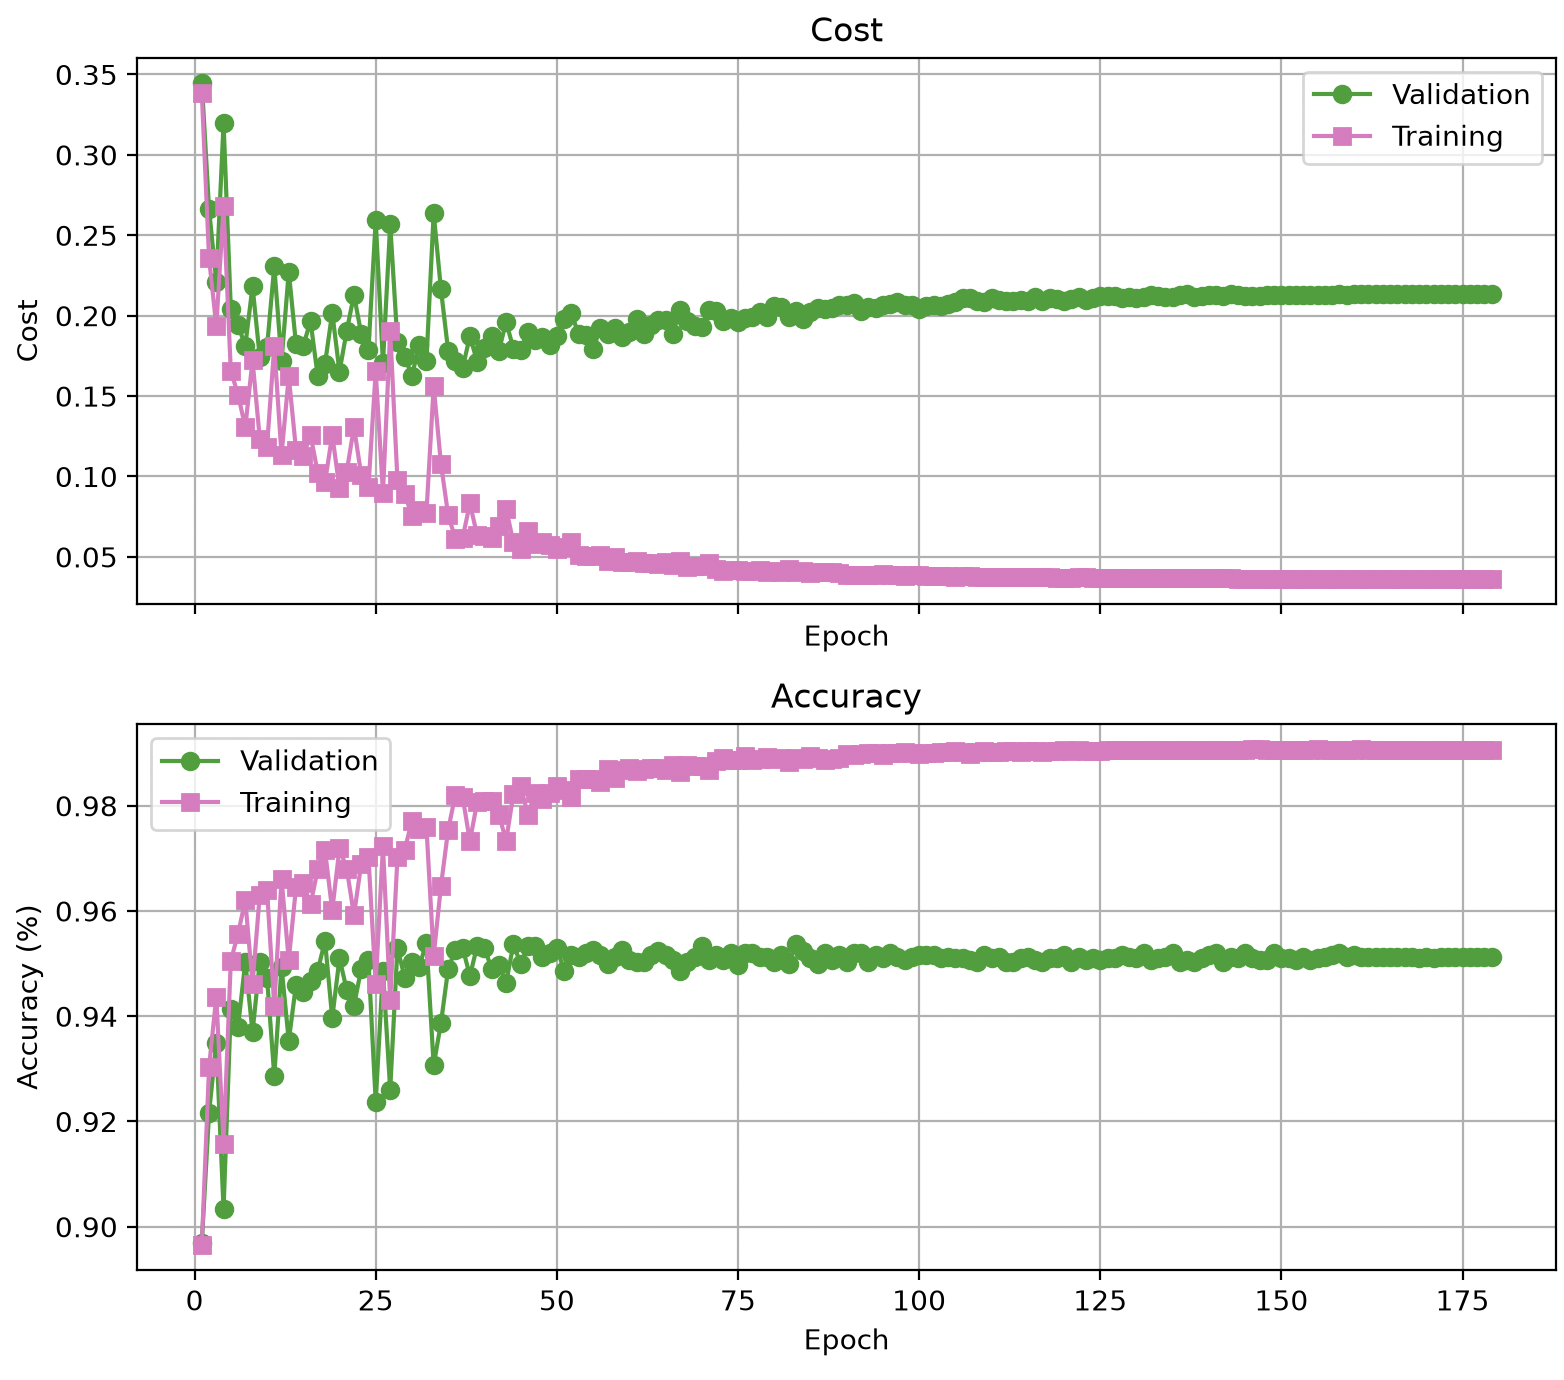

**Figure 2 — With L2 and dropout, after correcting the L2 update**

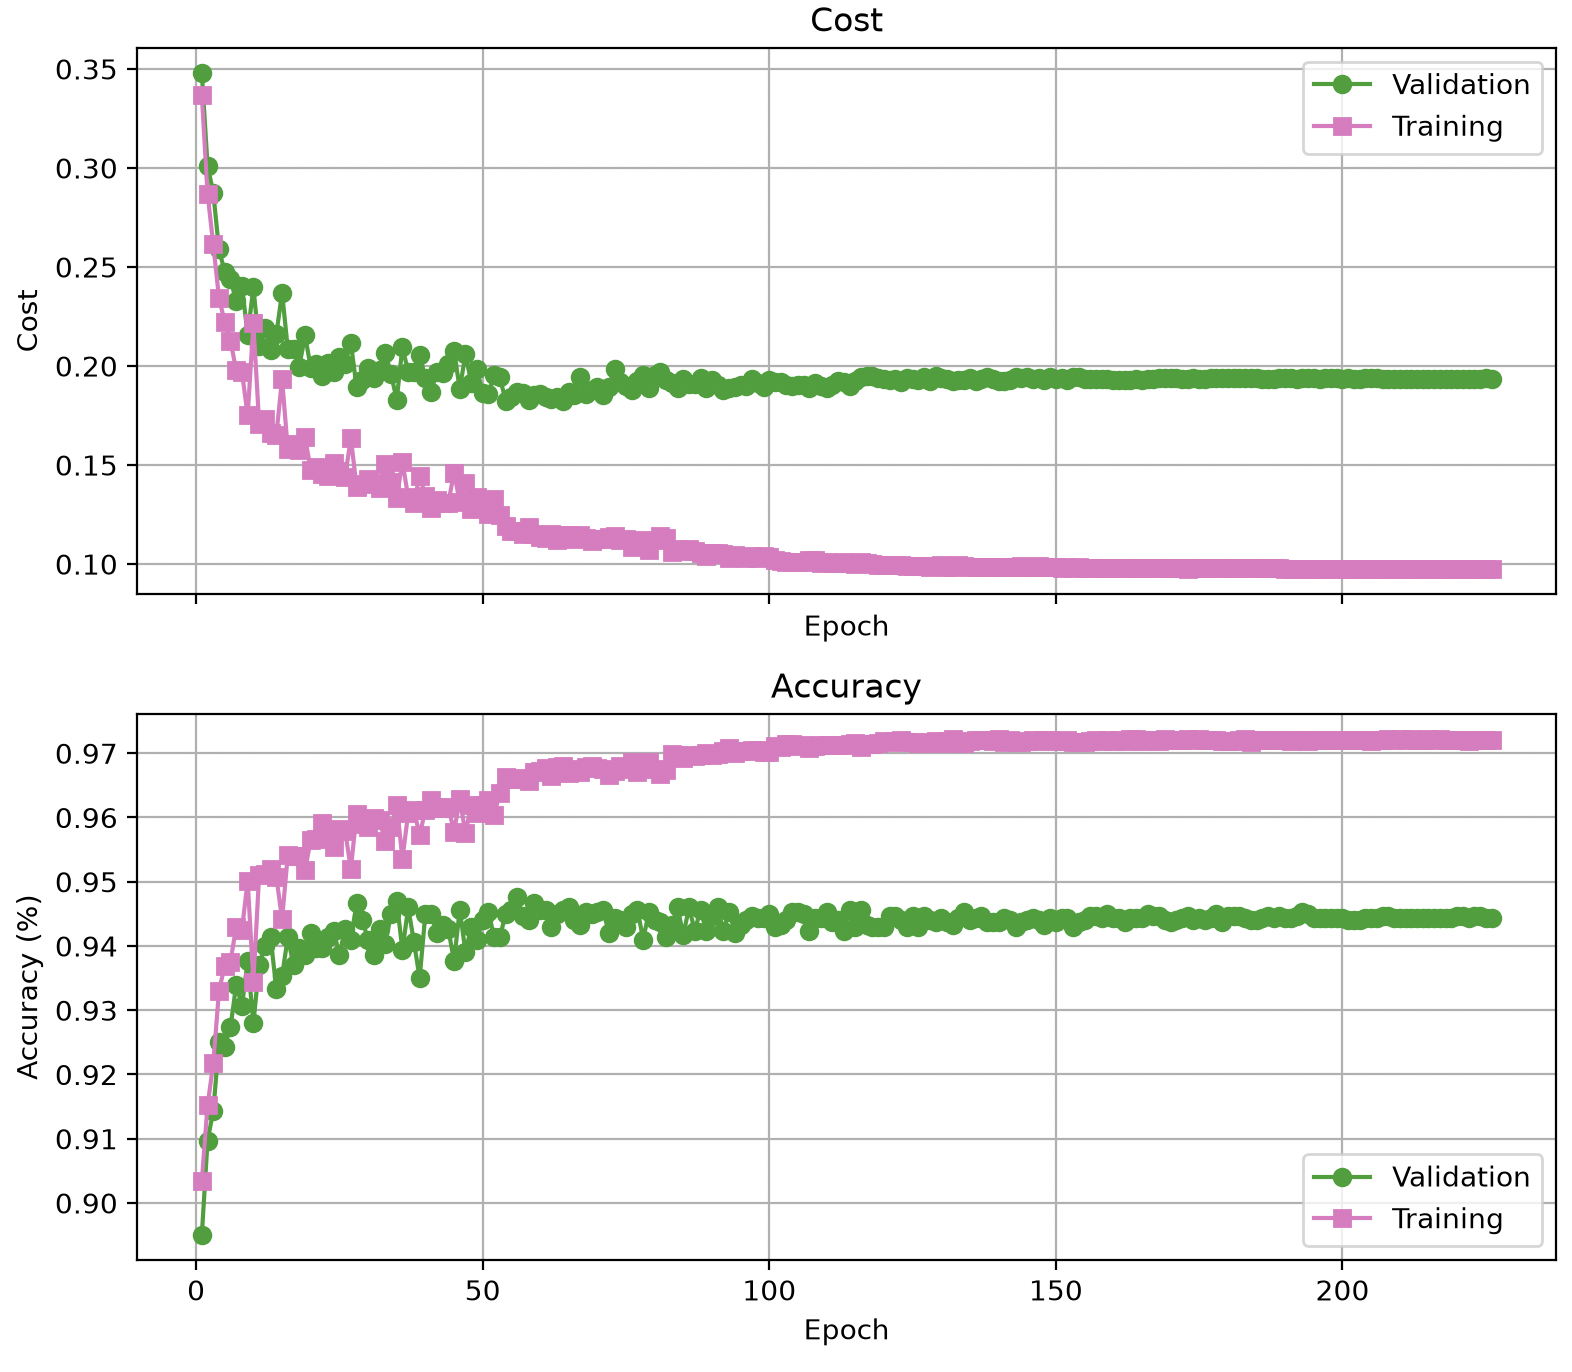

#### 4.1.2 What the Two Figures Show

| Observation | Without regularization: Figure 1 | With regularization: Figure 2 |
| :--- | :--- | :--- |
| Training cross-entropy | Falls toward about 0.04. | Falls toward about 0.10 and becomes approximately flat; no sustained late rise is visible. |
| Validation cross-entropy | Initially improves, then rises toward about 0.21 while training loss continues falling. | Falls toward about 0.18–0.19, then stays near 0.19 with a slight rise from its earlier minimum. |
| Accuracy | Training approaches 99%; validation stays near 95%. | Training approaches 97.2%; validation stays near 94.4%, giving a smaller gap of about 2.8 percentage points. |
| Interpretation | Strong evidence of overfitting after the early validation-loss minimum. | Training fit is restrained and the late curves are more stable, but validation accuracy is not higher than in Figure 1. |

The accuracy axes show fractions despite the label “Accuracy (%)”: 0.95 means 95%.

<p style="font-size: 1.2em;"><strong>The key evidence for overfitting is that training keeps improving while validation stops improving or gets worse.</strong></p>

In Figure 1, lower training loss and nearly 99% training accuracy do not translate into better validation performance. The widening gap shows that the extra fitting is becoming specific to the training examples. Validation accuracy can remain near 95% while validation cross-entropy rises: probabilities may deteriorate, including more confident incorrect predictions, without many argmax decisions changing.

**What changed in the revised Figure 2?** The training loss settles near 0.10 instead of approaching 0.04, and training accuracy settles near 97.2% instead of 99%. The training–validation gap is smaller. 


#### 4.1.3 Why Overfitting Happens

The weights are optimized using a finite training sample. A flexible network can learn general digit patterns, but continued fitting can also capture sample-specific handwriting details, noise, or accidental correlations that do not transfer to other images.

**More training therefore does not always mean better generalization.** Validation data helps identify when additional training no longer improves performance on examples outside the training set. Regularization constrains the solutions the model can learn; early stopping limits how long it continues fitting.

#### 4.1.4 L2 Regularization: Penalize Large Weights

For mean training cross-entropy $J_{\text{data}}$ and $N$ training examples, a standard L2-regularized objective is:

$$
J_{\text{total}}=J_{\text{data}}
+\frac{\lambda}{2N}\sum_l\|W^{[l]}\|_F^2.
$$

Its weight gradient adds $\lambda W^{[l]}/N$, giving:

$$
W^{[l]}\leftarrow
W^{[l]}-\alpha\left(dW^{[l]}+\frac{\lambda}{N}W^{[l]}\right)
=\left(1-\frac{\alpha\lambda}{N}\right)W^{[l]}-\alpha dW^{[l]}.
$$

**Why L2 can reduce overfitting:** penalizing large weights constrains how freely the model can fit training-specific details, encouraging solutions that may generalize better to unseen examples. 

**L2 in this implementation:**

```python
w1 -= lr * (dw1 + (lambda_ * w1) / X_train_split.shape[0])
w2 -= lr * (dw2 + (lambda_ * w2) / X_train_split.shape[0])
w3 -= lr * (dw3 + (lambda_ * w3) / X_train_split.shape[0])
```

Each weight update combines **the data-loss gradient** `dw` with **the L2 gradient** `lambda_ * w / N`, where $N$ is the number of training examples. The data gradients already average over the current batch, so only the L2 term is divided by $N$ here. The learning rate scales the combined gradient; biases use their ordinary gradient updates without an L2 penalty.

The curves plot **cross-entropy alone**, not cross-entropy plus the L2 penalty. Training and validation metrics are both evaluated without dropout, so they describe the full network's predictions under the same evaluation conditions.

#### 4.1.5 Dropout: Randomly Remove Activations During Training

For a hidden activation matrix $A$, inverted dropout uses:

$$
M_{ij}\sim\operatorname{Bernoulli}(p_{\text{keep}}),
\qquad
\widetilde A=A\odot\frac{M}{p_{\text{keep}}}.
$$

With $p_{\text{keep}}=0.9$, each activation is independently kept with probability 0.9. Given an activation value $a$, the scaling preserves its expectation over masks:

$$
\mathbb E\left[a\frac{M}{p_{\text{keep}}}\,\middle|\,a\right]
=a\frac{\mathbb E[M]}{p_{\text{keep}}}=a.
$$

**Why dropout can reduce overfitting:** randomly removing activations discourages excessive reliance on particular combinations of features, encouraging representations that remain useful across different masks and may generalize better to unseen examples. In backpropagation, dropped activations pass no gradient. During validation and testing, dropout is disabled and no extra scaling is needed with this inverted-dropout convention.




#### 4.1.6 Data Augmentation

##### 4.1.6.1 Principle: Learn the Digit, Not Its Exact Position

This implementation translates each training image independently by up to two pixels horizontally and vertically. Newly exposed pixels are filled with zero; pixels moved outside the image are cropped. The label is kept unchanged, provided the small shift preserves the digit's identity.

**Why it can reduce overfitting:** encountering different positions of the same digit discourages reliance on training-specific pixel locations and encourages features that remain useful after small translations. The number of stored examples does not increase; a new random version is generated when each example enters a training batch.

Instead of fitting only the original image $x_i$, training samples transformations $T$:

$$
J_{\mathrm{aug}}(W)
=\frac1N\sum_{i=1}^{N}\mathbb E_T
\left[\ell(f_W(T(x_i)),y_i)\right].
$$

Randomly shifting each batch approximates this augmented data-loss objective. L2 and dropout remain enabled. Validation and test images are not augmented.

##### 4.1.6.2 Augmentation Code and Explanation

| Operation | Meaning |
| :--- | :--- |
| `reshape(-1, 28, 28)` | Recover the two spatial dimensions from the `(B, 784)` batch. |
| `np.zeros_like(images)` | Allocate a new image batch with black backgrounds and the same dtype. Preserve the original input array. |
| `integers(-max_shift, max_shift + 1, size=(B, 2))` | Generate independent `(dy, dx)` offsets for each image; with `max_shift=2`, each coordinate is sampled from −2 through 2. |
| `src_y`, `src_x` | Select the original pixels that remain inside the frame after translation. |
| `dst_y`, `dst_x` | Select where those pixels belong in the output image. |
| Copy the selected rectangle | Move overlapping pixels without wrapping edge pixels to the opposite side. |
| `reshape(X_batch.shape)` | Return `(B, 784)`, so the existing matrix operations still apply. |

Positive `dy` moves down; positive `dx` moves right. For a rightward shift of two pixels, `src_x = slice(0, 26)` and `dst_x = slice(2, 28)`: the original first 26 columns become the output's last 26 columns, while the first two output columns remain zero.

**Pipeline:** original batch → restore image shape → sample offsets → translate with zero fill → flatten → existing forward and backward passes.

A separate `augmentation_rng` keeps augmentation draws from consuming the random numbers used by initialization, shuffling, and dropout. It reproduces the sequence across runs, while generating fresh offsets on successive calls. The backward pass uses the same augmented `X_train_batch` that entered the forward pass.

**Augmentation code and its placement in the training loop:**

These are all the additions to the existing script; the network, L2 update, dropout, and training controls are retained.

**1. Add the helper beside the other functions.** It uses the script's existing NumPy import:

```python
def augment_batch(X_batch, augmentation_rng, max_shift=2):
    """Shift each 28x28 image independently; fill uncovered pixels with zero."""
    images = X_batch.reshape(-1, 28, 28)
    shifted = np.zeros_like(images)
    offsets = augmentation_rng.integers(-max_shift, max_shift + 1,
                                        size=(len(images), 2))
    for image_index, (dy, dx) in enumerate(offsets):
        # Copy overlapping pixels; do not wrap edge pixels to the opposite side.
        src_y = slice(max(0, -dy), min(28, 28 - dy))
        src_x = slice(max(0, -dx), min(28, 28 - dx))
        dst_y = slice(max(0, dy), min(28, 28 + dy))
        dst_x = slice(max(0, dx), min(28, 28 + dx))
        shifted[image_index, dst_y, dst_x] = images[image_index, src_y, src_x]
    return shifted.reshape(X_batch.shape)
```

**2. Add the configuration after `batch_size = 32`:**

```python
max_shift = 2  # Set to 0 for the no-augmentation control.
augmentation_rng = default_rng(seed=42)
```

**3. Inside the existing mini-batch loop, use the following batch preparation immediately before the forward pass:**

```python
X_train_batch = X_train_split[j:end]
y_train_batch = y_train_split[j:end]
X_train_batch = augment_batch(X_train_batch, augmentation_rng, max_shift)
```

The full training script containing these additions is `IM 2-2 Handwritten Digit Recognition`. Its epoch-level training metrics still use the original `X_train_split`, and its validation/test metrics use their original inputs, all without dropout. Thus, the plotted training curve is **not the loss of the randomly augmented training batches**.



##### 4.1.6.3 Complete Training Code

The following cell contains the complete current training script, including data loading, augmentation, L2, dropout, forward and backward propagation, learning-rate reduction, early stopping, testing, and plotting. It is copied unchanged from `IM 2-2 Handwritten Digit Recognition`. Run it from the same working directory as the original script so the relative data paths resolve correctly.


In [ ]:
import ssl
import certifi
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from numpy.random import default_rng

#Import the required libraries
# Fix HTTPS certificate verification before importing torchvision
ssl._create_default_https_context = (
    lambda: ssl.create_default_context(cafile=certifi.where())
)

# Download MNIST datasets
train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
)

# Read raw MNIST binary files
def load_dataset(path, is_label=False):
    offset = 8 if is_label else 16

    with open(path, "rb") as file:
        data = np.frombuffer(
            file.read(),
            dtype=np.uint8,
            offset=offset,
        )

    return data


# File paths
data_dir = "./data/MNIST/raw"

X_train = load_dataset(
    f"{data_dir}/train-images-idx3-ubyte"
)

y_train = load_dataset(
    f"{data_dir}/train-labels-idx1-ubyte",
    is_label=True,
)

X_test = load_dataset(
    f"{data_dir}/t10k-images-idx3-ubyte"
)

y_test = load_dataset(
    f"{data_dir}/t10k-labels-idx1-ubyte",
    is_label=True,
)

# Reshape images: 28 x 28 = 784 pixels
X_train = X_train.reshape(60000, 784)
X_test = X_test.reshape(10000, 784)


'''# Check the results
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Visualize some samples from the training dataset
fig, axes = plt.subplots(4, 10, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image, cmap="gray")
    ax.set_title(f"label = {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()'''


# Convert pixels from 0-255 to 0.0-1.0, avoiding overflow when multiplying by weights
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# One-hot encode labels
identity_matrix = np.eye(10)

y_train = identity_matrix[y_train]
y_test = identity_matrix[y_test]


#Some useful functions for the neural network
def relu(x):
    return np.maximum(0, x)

def batch_softmax(x):
    row_max = np.max(x, axis = 1, keepdims = True)
    exp_x = np.exp(x - row_max)
    return exp_x / np.sum(exp_x, axis = 1, keepdims = True)

def batch_cross_entropy(y, y_hat): 
    total_loss = -np.sum(y * np.log(y_hat + 1e-15), axis=1, keepdims=True) #prevent log 0
    return np.mean(total_loss)

def diff_relu(x):
    return (x > 0).astype(float)


def augment_batch(X_batch, augmentation_rng, max_shift=2):
    """Shift each 28x28 image independently; fill uncovered pixels with zero."""
    images = X_batch.reshape(-1, 28, 28)
    shifted = np.zeros_like(images)
    offsets = augmentation_rng.integers(-max_shift, max_shift + 1,
                                        size=(len(images), 2))
    for image_index, (dy, dx) in enumerate(offsets):
        # Copy overlapping pixels; do not wrap edge pixels to the opposite side.
        src_y = slice(max(0, -dy), min(28, 28 - dy))
        src_x = slice(max(0, -dx), min(28, 28 - dx))
        dst_y = slice(max(0, dy), min(28, 28 + dy))
        dst_x = slice(max(0, dx), min(28, 28 + dx))
        shifted[image_index, dst_y, dst_x] = images[image_index, src_y, src_x]
    return shifted.reshape(X_batch.shape)


#Initialize weights and biases
rng = default_rng(seed = 42)
limit = np.sqrt(6 / 784)
w1 = rng.uniform(low = -limit, high = limit, size = (784, 16)) #Mind the defference between the regression and the NN, because Regression only passes one input, while NN passes a batch of inputs, so after one Node, the result is still a matix rather than a value.
limit = np.sqrt(6 / 16)
w2 = rng.uniform(low=-limit, high=limit, size=(16, 16))
w3 = rng.uniform(low=-limit, high=limit, size=(16, 10))

b1 = np.zeros((1, 16))
b2 = np.zeros((1, 16))
b3 = np.zeros((1, 10))


#Train-validation split
split = int(0.95 * len(X_train))
shuffle = rng.permutation(len(X_train))
X_train, y_train = X_train[shuffle], y_train[shuffle]
X_train_split = X_train[:split]
y_train_split = y_train[:split]
X_val_split = X_train[split:]
y_val_split = y_train[split:]

#Iteration parameters
epochs = 1000
batch_size = 32
max_shift = 2  # Random translation by up to 2 pixels; set to 0 to disable.
augmentation_rng = default_rng(seed=42)  # Separate from weights/shuffling/dropout.

# Early stopping parameters
patience  = 18
minidelta = 0.0001
patience_counter = 0

#checkpoint parameters
best_val_cost = np.inf
best_w1, best_w2, best_w3 = None, None, None
best_b1, best_b2, best_b3 = None, None, None

#lr reduction parameters
lr = 0.05 
min_lr = 1e-6
lr_reduction_factor = 0.5
lr_maxcon_reductions = 8 
lr_reduction_counter = 0

#L2 regularization parameters
lambda_ = 0.15

#Dropout parameters
pkeep = 0.9

#Tracking validation and training cost and accuracy
batches = (len(X_train_split) + batch_size - 1) // batch_size
val_cost_list = []
val_accuracy = []
train_cost_list = []
train_accuracy = []


for i in range(epochs):
    shuffle = rng.permutation(len(X_train_split))
    X_train_split, y_train_split = X_train_split[shuffle], y_train_split[shuffle]
    batch_count = 0
    for j in range(0, len(X_train_split), batch_size):
        batch_count += 1
        end = j + batch_size
        X_train_batch = X_train_split[j:end]
        y_train_batch = y_train_split[j:end]
        X_train_batch = augment_batch(X_train_batch, augmentation_rng, max_shift)

        #Forward Pass
        z1 = np.dot(X_train_batch, w1) + b1
        a1 = relu(z1)

        a1_mask = rng.binomial(1, pkeep, size = a1.shape)
        a1_mask = a1_mask.astype(float)
        a1 *= a1_mask / pkeep

        z2 = np.dot(a1, w2) + b2
        a2 = relu(z2)

        a2_mask = rng.binomial(1, pkeep, size = a2.shape)
        a2_mask = a2_mask.astype(float)
        a2 *= a2_mask / pkeep

        z3 = np.dot(a2, w3) + b3
        a3 = batch_softmax(z3)

        cost = batch_cross_entropy(y_train_batch, a3)

        #Backward Pass
        delta3 = a3 - y_train_batch
        delta2 = np.dot(delta3, w3.T) * diff_relu(z2) * (a2_mask / pkeep)
        delta1 = np.dot(delta2, w2.T) * diff_relu(z1) * (a1_mask / pkeep)

        dw3 = np.dot(a2.T, delta3) / X_train_batch.shape[0]
        dw2 = np.dot(a1.T, delta2) / X_train_batch.shape[0]
        dw1 = np.dot(X_train_batch.T, delta1) / X_train_batch.shape[0]
        

        db3 = np.sum(delta3, axis=0, keepdims=True) / X_train_batch.shape[0]
        db2 = np.sum(delta2, axis=0, keepdims=True) / X_train_batch.shape[0]
        db1 = np.sum(delta1, axis=0, keepdims=True) / X_train_batch.shape[0]    

        w1 -= (lr * (dw1 + (lambda_ * w1) / X_train_split.shape[0]))
        w2 -= (lr * (dw2 + (lambda_ * w2) / X_train_split.shape[0]))
        w3 -= (lr * (dw3 + (lambda_ * w3) / X_train_split.shape[0]))

        b1 -= lr * db1
        b2 -= lr * db2
        b3 -= lr * db3
    
    

    #Validation
    z1_val = np.dot(X_val_split, w1) + b1
    a1_val = relu(z1_val)
    z2_val = np.dot(a1_val, w2) + b2
    a2_val = relu(z2_val)
    z3_val = np.dot(a2_val, w3) + b3
    a3_val = batch_softmax(z3_val)

    val_cost = batch_cross_entropy(y_val_split, a3_val)
    val_cost_list.append(val_cost)
    
    predictions = np.argmax(a3_val, axis=1)
    labels = np.argmax(y_val_split, axis=1)
    accuracy = np.mean(predictions == labels)
    val_accuracy.append(accuracy)

    #Training
    z1_train = np.dot(X_train_split, w1) + b1
    a1_train = relu(z1_train)   
    z2_train = np.dot(a1_train, w2) + b2
    a2_train = relu(z2_train)
    z3_train = np.dot(a2_train, w3) + b3
    a3_train = batch_softmax(z3_train)

    train_cost = batch_cross_entropy(y_train_split, a3_train)
    train_cost_list.append(train_cost)
    train_predictions = np.argmax(a3_train, axis=1)
    train_labels = np.argmax(y_train_split, axis=1)
    train_acc = np.mean(train_predictions == train_labels)
    train_accuracy.append(train_acc)
    
    #Print progress every 100 epochs
    if (i + 1) % 100 == 0:
        print(f"Epoch {i + 1}/{epochs}, Validation Cost: {val_cost:.4f}, Training Cost: {train_cost:.4f}")

    # Early Stopping & lr reduction
    if val_cost < best_val_cost:
        best_w1, best_w2, best_w3 = np.copy(w1), np.copy(w2), np.copy(w3)
        best_b1, best_b2, best_b3 = np.copy(b1), np.copy(b2), np.copy(b3)

    if best_val_cost - val_cost > minidelta:
        best_val_cost = val_cost
        patience_counter = 0
        lr_reduction_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            if lr * lr_reduction_factor >= min_lr and lr_reduction_counter < lr_maxcon_reductions:
                lr *= lr_reduction_factor
                print(f"Epoch {i + 1}: Reducing learning rate to {lr:.6f}")
                patience_counter = 0
                lr_reduction_counter += 1
            else:
                print(f"Epoch {i + 1}: Early stopping triggered.")
                break



test_z1 = np.dot(X_test, best_w1) + best_b1
test_a1 = relu(test_z1)
test_z2 = np.dot(test_a1, best_w2) + best_b2
test_a2 = relu(test_z2)
test_z3 = np.dot(test_a2, best_w3) + best_b3
test_a3 = batch_softmax(test_z3)

test_predictions = np.argmax(test_a3, axis=1)
test_labels = np.argmax(y_test, axis=1)
test_accuracy = np.mean(np.equal(test_predictions, test_labels))
print(f"Test Accuracy: {test_accuracy:.4f}")



fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# Cost graph
epoch_numbers = range(1, len(val_cost_list) + 1)
ax1.plot(epoch_numbers, val_cost_list, marker="o", color="tab:green", label="Validation")
ax1.plot(epoch_numbers, train_cost_list, marker="s", color="tab:pink", label="Training")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cost")
ax1.set_title("Cost")
ax1.grid(True)
ax1.legend()

# Accuracy graph
ax2.plot(epoch_numbers, val_accuracy, marker="o", color="tab:green", label="Validation")
ax2.plot(epoch_numbers, train_accuracy, marker="s", color="tab:pink", label="Training")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Accuracy")
ax2.grid(True)
ax2.legend()


plt.tight_layout()
plt.show()


##### 4.1.6.4 Results: A Smaller Gap, but Lower Test Accuracy

**Figure 3 — L2 + dropout + random translation**

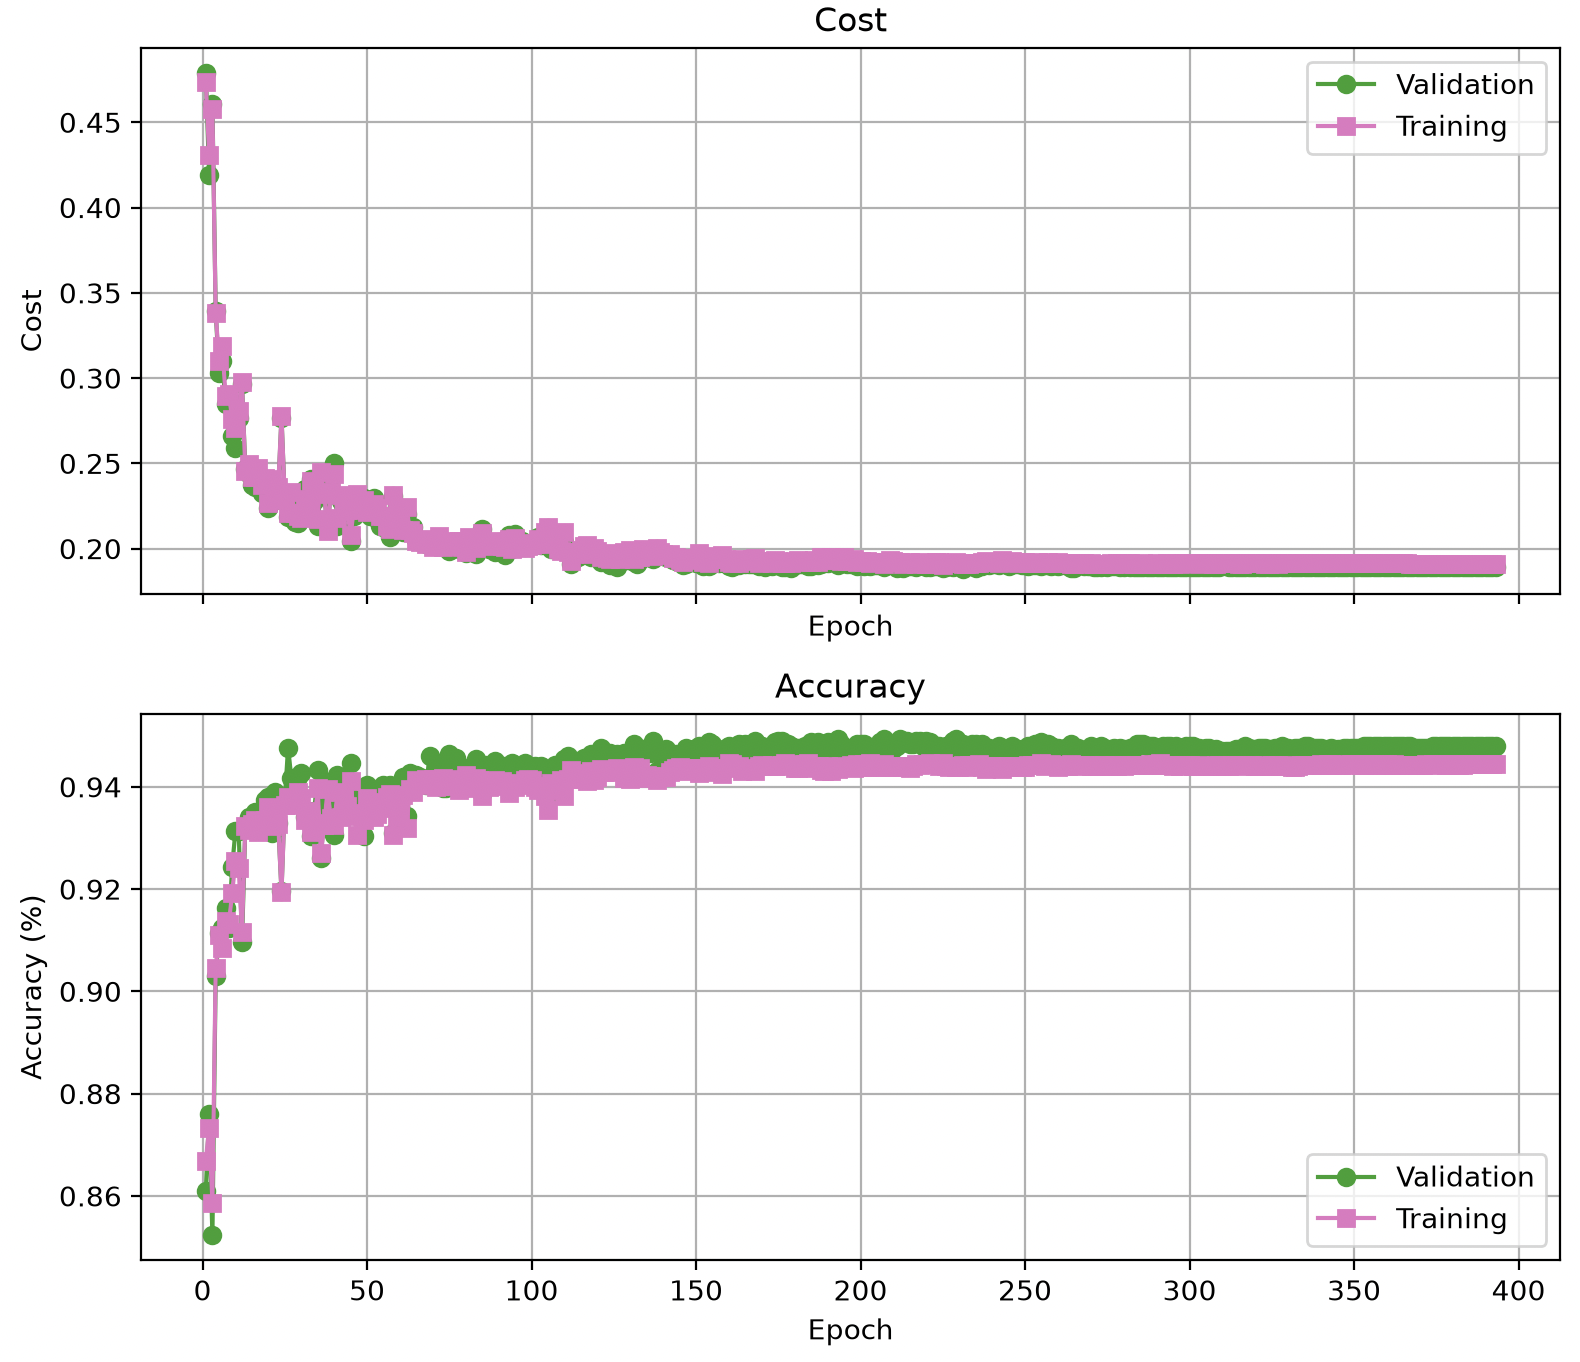

Compare this with **Figure 2 in Section 4.1.1**, which uses L2 and dropout without augmentation. Values below are approximate visual readings of the late curves; test accuracies are the reported results, not values extracted from the graphs.

| Measure | L2 + dropout, no augmentation | L2 + dropout + augmentation |
| :--- | :--- | :--- |
| Training cross-entropy | About 0.10 | About 0.19 |
| Validation cross-entropy | About 0.19 | About 0.19 |
| Training accuracy | About 97.2% | About 94.5% |
| Validation accuracy | About 94.4% | About 94.8% |
| Training–validation accuracy difference | Training higher by about 2.8 percentage points | Less than about 0.5 percentage points; validation is slightly higher |
| Reported test accuracy | 95.29% | 94.54% |

**What supports reduced overfitting?** Without augmentation, the model fits training images noticeably better than validation images. With augmentation, the loss curves nearly coincide and the accuracies remain close, without a sustained late validation-loss rise while training loss falls. This supports a reduced training-specific fitting advantage.

Validation accuracy being slightly higher than training accuracy is not inherently an error. The two finite sets can differ in difficulty, and augmented training does not directly minimize the plotted loss on original training images. Since both curves are evaluated without dropout, their ordering should not simply be attributed to active dropout at evaluation time.

**Why might test accuracy fall from 95.29% to 94.54% despite the smaller gap?** The decrease is **0.75 percentage points**, or 75 fewer correct predictions on the 10,000-image test set. One possible explanation I am considering is:

- **The transformation may not perfectly match the test distribution.** MNIST digits are generally centered. Translation teaches tolerance to off-center images, which can be useful, but may sacrifice precision on centered examples. Cropping can also remove a stroke when it lies near an edge. More specifically, augmentation exposes the model to shifted images, while the test images are generally centered. Training without augmentation may therefore match that particular test distribution more closely—somewhat like a student practicing questions that closely resemble those on an exam. This is a possible explanation, not a confirmed cause.

**My interpretation:** augmentation substantially reduced the training–validation gap in this run, which I interpret as evidence of reduced overfitting.

### 4.2 Improving the Model and Other Considerations

#### 4.2.1 Increasing Width

##### 4.2.1.1 Structure and Complete Code

The wider network changes **784 → 16 → 16 → 10** to **784 → 32 → 32 → 10**, allowing each hidden layer to learn more features in parallel. The code below changes only weight/bias dimensions and their fan-in initialization scales; augmentation, L2, dropout, and the training policy are retained.



100.0%
100.0%
100.0%
100.0%


Epoch 91: Reducing learning rate to 0.025000
Epoch 100/1000, Validation Cost: 0.1077, Training Cost: 0.0942
Epoch 130: Reducing learning rate to 0.012500
Epoch 169: Reducing learning rate to 0.006250
Epoch 192: Reducing learning rate to 0.003125
Epoch 200/1000, Validation Cost: 0.1027, Training Cost: 0.0839
Epoch 239: Reducing learning rate to 0.001563
Epoch 257: Reducing learning rate to 0.000781
Epoch 275: Reducing learning rate to 0.000391
Epoch 293: Reducing learning rate to 0.000195
Epoch 300/1000, Validation Cost: 0.1027, Training Cost: 0.0832
Epoch 311: Reducing learning rate to 0.000098
Epoch 329: Reducing learning rate to 0.000049
Epoch 347: Reducing learning rate to 0.000024
Epoch 365: Reducing learning rate to 0.000012
Epoch 383: Early stopping triggered.
Test Accuracy: 0.9753


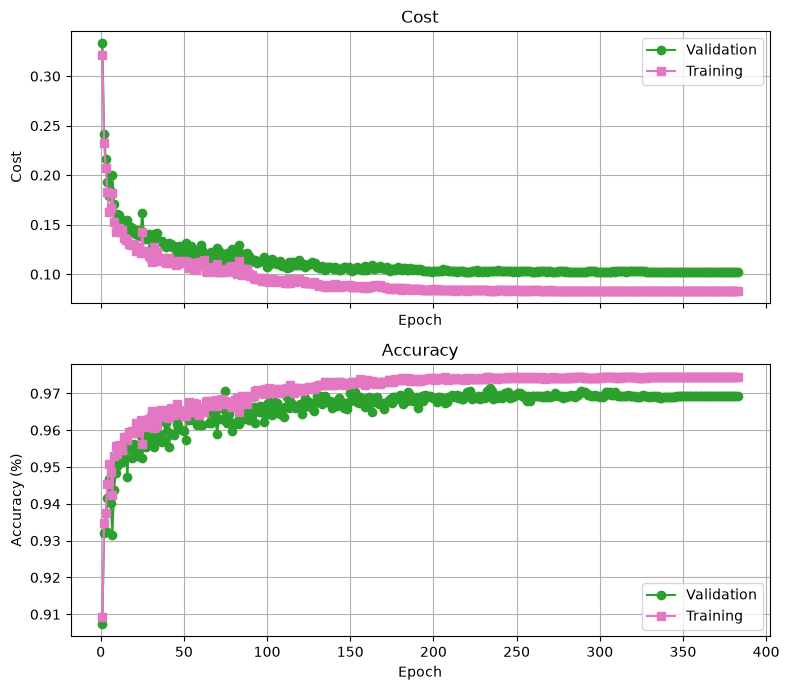

In [4]:
import ssl
import certifi
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from numpy.random import default_rng

#Import the required libraries
# Fix HTTPS certificate verification before importing torchvision
ssl._create_default_https_context = (
    lambda: ssl.create_default_context(cafile=certifi.where())
)

# Download MNIST datasets
train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
)

# Read raw MNIST binary files
def load_dataset(path, is_label=False):
    offset = 8 if is_label else 16

    with open(path, "rb") as file:
        data = np.frombuffer(
            file.read(),
            dtype=np.uint8,
            offset=offset,
        )

    return data


# File paths
data_dir = "./data/MNIST/raw"

X_train = load_dataset(
    f"{data_dir}/train-images-idx3-ubyte"
)

y_train = load_dataset(
    f"{data_dir}/train-labels-idx1-ubyte",
    is_label=True,
)

X_test = load_dataset(
    f"{data_dir}/t10k-images-idx3-ubyte"
)

y_test = load_dataset(
    f"{data_dir}/t10k-labels-idx1-ubyte",
    is_label=True,
)

# Reshape images: 28 x 28 = 784 pixels
X_train = X_train.reshape(60000, 784)
X_test = X_test.reshape(10000, 784)


'''# Check the results
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Visualize some samples from the training dataset
fig, axes = plt.subplots(4, 10, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image, cmap="gray")
    ax.set_title(f"label = {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()'''


# Convert pixels from 0-255 to 0.0-1.0, avoiding overflow when multiplying by weights
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# One-hot encode labels
identity_matrix = np.eye(10)

y_train = identity_matrix[y_train]
y_test = identity_matrix[y_test]


#Some useful functions for the neural network
def relu(x):
    return np.maximum(0, x)

def batch_softmax(x):
    row_max = np.max(x, axis = 1, keepdims = True)
    exp_x = np.exp(x - row_max)
    return exp_x / np.sum(exp_x, axis = 1, keepdims = True)

def batch_cross_entropy(y, y_hat): 
    total_loss = -np.sum(y * np.log(y_hat + 1e-15), axis=1, keepdims=True) #prevent log 0
    return np.mean(total_loss)

def diff_relu(x):
    return (x > 0).astype(float)


def augment_batch(X_batch, augmentation_rng, max_shift=2):
    """Shift each 28x28 image independently; fill uncovered pixels with zero."""
    images = X_batch.reshape(-1, 28, 28)
    shifted = np.zeros_like(images)
    offsets = augmentation_rng.integers(-max_shift, max_shift + 1,
                                        size=(len(images), 2))
    for image_index, (dy, dx) in enumerate(offsets):
        # Copy overlapping pixels; do not wrap edge pixels to the opposite side.
        src_y = slice(max(0, -dy), min(28, 28 - dy))
        src_x = slice(max(0, -dx), min(28, 28 - dx))
        dst_y = slice(max(0, dy), min(28, 28 + dy))
        dst_x = slice(max(0, dx), min(28, 28 + dx))
        shifted[image_index, dst_y, dst_x] = images[image_index, src_y, src_x]
    return shifted.reshape(X_batch.shape)


#Initialize weights and biases
rng = default_rng(seed = 42)
limit = np.sqrt(6 / 784)
w1 = rng.uniform(low = -limit, high = limit, size = (784, 32)) #Mind the defference between the regression and the NN, because Regression only passes one input, while NN passes a batch of inputs, so after one Node, the result is still a matix rather than a value.
limit = np.sqrt(6 / 32)
w2 = rng.uniform(low=-limit, high=limit, size=(32, 32))
w3 = rng.uniform(low=-limit, high=limit, size=(32, 10))

b1 = np.zeros((1, 32))
b2 = np.zeros((1, 32))
b3 = np.zeros((1, 10))


#Train-validation split
split = int(0.95 * len(X_train))
shuffle = rng.permutation(len(X_train))
X_train, y_train = X_train[shuffle], y_train[shuffle]
X_train_split = X_train[:split]
y_train_split = y_train[:split]
X_val_split = X_train[split:]
y_val_split = y_train[split:]

#Iteration parameters
epochs = 1000
batch_size = 32
max_shift = 2  # Random translation by up to 2 pixels; set to 0 to disable.
augmentation_rng = default_rng(seed=42)  # Separate from weights/shuffling/dropout.

# Early stopping parameters
patience  = 18
minidelta = 0.0001
patience_counter = 0

#checkpoint parameters
best_val_cost = np.inf
best_w1, best_w2, best_w3 = None, None, None
best_b1, best_b2, best_b3 = None, None, None

#lr reduction parameters
lr = 0.05 
min_lr = 1e-6
lr_reduction_factor = 0.5
lr_maxcon_reductions = 8 
lr_reduction_counter = 0

#L2 regularization parameters
lambda_ = 0.15

#Dropout parameters
pkeep = 0.9

#Tracking validation and training cost and accuracy
batches = (len(X_train_split) + batch_size - 1) // batch_size
val_cost_list = []
val_accuracy = []
train_cost_list = []
train_accuracy = []


for i in range(epochs):
    shuffle = rng.permutation(len(X_train_split))
    X_train_split, y_train_split = X_train_split[shuffle], y_train_split[shuffle]
    batch_count = 0
    for j in range(0, len(X_train_split), batch_size):
        batch_count += 1
        end = j + batch_size
        X_train_batch = X_train_split[j:end]
        y_train_batch = y_train_split[j:end]
        X_train_batch = augment_batch(X_train_batch, augmentation_rng, max_shift)

        #Forward Pass
        z1 = np.dot(X_train_batch, w1) + b1
        a1 = relu(z1)

        a1_mask = rng.binomial(1, pkeep, size = a1.shape)
        a1_mask = a1_mask.astype(float)
        a1 *= a1_mask / pkeep

        z2 = np.dot(a1, w2) + b2
        a2 = relu(z2)

        a2_mask = rng.binomial(1, pkeep, size = a2.shape)
        a2_mask = a2_mask.astype(float)
        a2 *= a2_mask / pkeep

        z3 = np.dot(a2, w3) + b3
        a3 = batch_softmax(z3)

        cost = batch_cross_entropy(y_train_batch, a3)

        #Backward Pass
        delta3 = a3 - y_train_batch
        delta2 = np.dot(delta3, w3.T) * diff_relu(z2) * (a2_mask / pkeep)
        delta1 = np.dot(delta2, w2.T) * diff_relu(z1) * (a1_mask / pkeep)

        dw3 = np.dot(a2.T, delta3) / X_train_batch.shape[0]
        dw2 = np.dot(a1.T, delta2) / X_train_batch.shape[0]
        dw1 = np.dot(X_train_batch.T, delta1) / X_train_batch.shape[0]
        

        db3 = np.sum(delta3, axis=0, keepdims=True) / X_train_batch.shape[0]
        db2 = np.sum(delta2, axis=0, keepdims=True) / X_train_batch.shape[0]
        db1 = np.sum(delta1, axis=0, keepdims=True) / X_train_batch.shape[0]    

        w1 -= (lr * (dw1 + (lambda_ * w1) / X_train_split.shape[0]))
        w2 -= (lr * (dw2 + (lambda_ * w2) / X_train_split.shape[0]))
        w3 -= (lr * (dw3 + (lambda_ * w3) / X_train_split.shape[0]))

        b1 -= lr * db1
        b2 -= lr * db2
        b3 -= lr * db3
    
    

    #Validation
    z1_val = np.dot(X_val_split, w1) + b1
    a1_val = relu(z1_val)
    z2_val = np.dot(a1_val, w2) + b2
    a2_val = relu(z2_val)
    z3_val = np.dot(a2_val, w3) + b3
    a3_val = batch_softmax(z3_val)

    val_cost = batch_cross_entropy(y_val_split, a3_val)
    val_cost_list.append(val_cost)
    
    predictions = np.argmax(a3_val, axis=1)
    labels = np.argmax(y_val_split, axis=1)
    accuracy = np.mean(predictions == labels)
    val_accuracy.append(accuracy)

    #Training
    z1_train = np.dot(X_train_split, w1) + b1
    a1_train = relu(z1_train)   
    z2_train = np.dot(a1_train, w2) + b2
    a2_train = relu(z2_train)
    z3_train = np.dot(a2_train, w3) + b3
    a3_train = batch_softmax(z3_train)

    train_cost = batch_cross_entropy(y_train_split, a3_train)
    train_cost_list.append(train_cost)
    train_predictions = np.argmax(a3_train, axis=1)
    train_labels = np.argmax(y_train_split, axis=1)
    train_acc = np.mean(train_predictions == train_labels)
    train_accuracy.append(train_acc)
    
    #Print progress every 100 epochs
    if (i + 1) % 100 == 0:
        print(f"Epoch {i + 1}/{epochs}, Validation Cost: {val_cost:.4f}, Training Cost: {train_cost:.4f}")

    # Early Stopping & lr reduction
    if val_cost < best_val_cost:
        best_w1, best_w2, best_w3 = np.copy(w1), np.copy(w2), np.copy(w3)
        best_b1, best_b2, best_b3 = np.copy(b1), np.copy(b2), np.copy(b3)

    if best_val_cost - val_cost > minidelta:
        best_val_cost = val_cost
        patience_counter = 0
        lr_reduction_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            if lr * lr_reduction_factor >= min_lr and lr_reduction_counter < lr_maxcon_reductions:
                lr *= lr_reduction_factor
                print(f"Epoch {i + 1}: Reducing learning rate to {lr:.6f}")
                patience_counter = 0
                lr_reduction_counter += 1
            else:
                print(f"Epoch {i + 1}: Early stopping triggered.")
                break



test_z1 = np.dot(X_test, best_w1) + best_b1
test_a1 = relu(test_z1)
test_z2 = np.dot(test_a1, best_w2) + best_b2
test_a2 = relu(test_z2)
test_z3 = np.dot(test_a2, best_w3) + best_b3
test_a3 = batch_softmax(test_z3)

test_predictions = np.argmax(test_a3, axis=1)
test_labels = np.argmax(y_test, axis=1)
test_accuracy = np.mean(np.equal(test_predictions, test_labels))
print(f"Test Accuracy: {test_accuracy:.4f}")



fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# Cost graph
epoch_numbers = range(1, len(val_cost_list) + 1)
ax1.plot(epoch_numbers, val_cost_list, marker="o", color="tab:green", label="Validation")
ax1.plot(epoch_numbers, train_cost_list, marker="s", color="tab:pink", label="Training")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cost")
ax1.set_title("Cost")
ax1.grid(True)
ax1.legend()

# Accuracy graph
ax2.plot(epoch_numbers, val_accuracy, marker="o", color="tab:green", label="Validation")
ax2.plot(epoch_numbers, train_accuracy, marker="s", color="tab:pink", label="Training")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Accuracy")
ax2.grid(True)
ax2.legend()


plt.tight_layout()
plt.show()


##### 4.2.1.2 Results and Interpretation

In this run, validation loss reached **0.1027** at epoch 200, compared with roughly 0.19 in the previous augmented baseline. Late training and validation accuracies were approximately **97.4% and 96.9%**, leaving a small gap of about 0.5 percentage points. Both datasets improved, supporting the idea that the earlier small network had limited capacity rather than merely needing stronger regularization.

The saved model achieved **97.53% test accuracy**, up from **94.54%**: an improvement of **2.99 percentage points**, or 299 additional correct predictions on 10,000 test images. Training stopped at epoch **383** after repeated lr reductions. These results show an improvement in this experiment, although one run does not establish that increasing width is generally better than increasing depth.


#### 4.2.2 Increasing Depth

##### 4.2.2.1 Structure and Complete Code

The deeper network changes **784 → 16 → 16 → 10** to **784 → 16 → 16 → 16 → 10**, adding one ReLU hidden layer to combine features further. The added layer has its own weights, biases, dropout mask, gradients, and checkpoint parameters; the rest of the training procedure is retained.



Epoch 100/1000, Validation Cost: 0.2269, Training Cost: 0.2271
Epoch 129: Reducing learning rate to 0.025000
Epoch 155: Reducing learning rate to 0.012500
Epoch 174: Reducing learning rate to 0.006250
Epoch 192: Reducing learning rate to 0.003125
Epoch 200/1000, Validation Cost: 0.1934, Training Cost: 0.1985
Epoch 210: Reducing learning rate to 0.001563
Epoch 228: Reducing learning rate to 0.000781
Epoch 246: Reducing learning rate to 0.000391
Epoch 264: Reducing learning rate to 0.000195
Epoch 282: Reducing learning rate to 0.000098
Epoch 300/1000, Validation Cost: 0.1929, Training Cost: 0.1965
Epoch 300: Reducing learning rate to 0.000049
Epoch 318: Early stopping triggered.
Test Accuracy: 0.9430


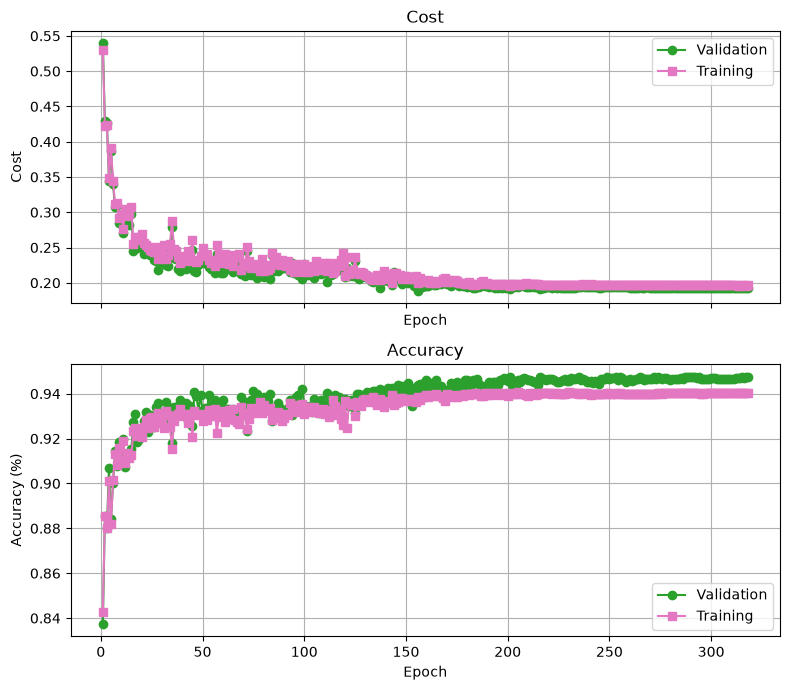

In [5]:
import ssl
import certifi
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from numpy.random import default_rng

#Import the required libraries
# Fix HTTPS certificate verification before importing torchvision
ssl._create_default_https_context = (
    lambda: ssl.create_default_context(cafile=certifi.where())
)

# Download MNIST datasets
train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
)

# Read raw MNIST binary files
def load_dataset(path, is_label=False):
    offset = 8 if is_label else 16

    with open(path, "rb") as file:
        data = np.frombuffer(
            file.read(),
            dtype=np.uint8,
            offset=offset,
        )

    return data


# File paths
data_dir = "./data/MNIST/raw"

X_train = load_dataset(
    f"{data_dir}/train-images-idx3-ubyte"
)

y_train = load_dataset(
    f"{data_dir}/train-labels-idx1-ubyte",
    is_label=True,
)

X_test = load_dataset(
    f"{data_dir}/t10k-images-idx3-ubyte"
)

y_test = load_dataset(
    f"{data_dir}/t10k-labels-idx1-ubyte",
    is_label=True,
)

# Reshape images: 28 x 28 = 784 pixels
X_train = X_train.reshape(60000, 784)
X_test = X_test.reshape(10000, 784)


'''# Check the results
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Visualize some samples from the training dataset
fig, axes = plt.subplots(4, 10, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image, cmap="gray")
    ax.set_title(f"label = {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()'''


# Convert pixels from 0-255 to 0.0-1.0, avoiding overflow when multiplying by weights
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# One-hot encode labels
identity_matrix = np.eye(10)

y_train = identity_matrix[y_train]
y_test = identity_matrix[y_test]


#Some useful functions for the neural network
def relu(x):
    return np.maximum(0, x)

def batch_softmax(x):
    row_max = np.max(x, axis = 1, keepdims = True)
    exp_x = np.exp(x - row_max)
    return exp_x / np.sum(exp_x, axis = 1, keepdims = True)

def batch_cross_entropy(y, y_hat): 
    total_loss = -np.sum(y * np.log(y_hat + 1e-15), axis=1, keepdims=True) #prevent log 0
    return np.mean(total_loss)

def diff_relu(x):
    return (x > 0).astype(float)


def augment_batch(X_batch, augmentation_rng, max_shift=2):
    """Shift each 28x28 image independently; fill uncovered pixels with zero."""
    images = X_batch.reshape(-1, 28, 28)
    shifted = np.zeros_like(images)
    offsets = augmentation_rng.integers(-max_shift, max_shift + 1,
                                        size=(len(images), 2))
    for image_index, (dy, dx) in enumerate(offsets):
        # Copy overlapping pixels; do not wrap edge pixels to the opposite side.
        src_y = slice(max(0, -dy), min(28, 28 - dy))
        src_x = slice(max(0, -dx), min(28, 28 - dx))
        dst_y = slice(max(0, dy), min(28, 28 + dy))
        dst_x = slice(max(0, dx), min(28, 28 + dx))
        shifted[image_index, dst_y, dst_x] = images[image_index, src_y, src_x]
    return shifted.reshape(X_batch.shape)


#Initialize weights and biases
rng = default_rng(seed = 42)
limit = np.sqrt(6 / 784)
w1 = rng.uniform(low = -limit, high = limit, size = (784, 16)) #Mind the defference between the regression and the NN, because Regression only passes one input, while NN passes a batch of inputs, so after one Node, the result is still a matix rather than a value.
limit = np.sqrt(6 / 16)
w2 = rng.uniform(low=-limit, high=limit, size=(16, 16))
w3 = rng.uniform(low=-limit, high=limit, size=(16, 16))
w4 = rng.uniform(low=-limit, high=limit, size=(16, 10))

b1 = np.zeros((1, 16))
b2 = np.zeros((1, 16))
b3 = np.zeros((1, 16))
b4 = np.zeros((1, 10))


#Train-validation split
split = int(0.95 * len(X_train))
shuffle = rng.permutation(len(X_train))
X_train, y_train = X_train[shuffle], y_train[shuffle]
X_train_split = X_train[:split]
y_train_split = y_train[:split]
X_val_split = X_train[split:]
y_val_split = y_train[split:]

#Iteration parameters
epochs = 1000
batch_size = 32
max_shift = 2  # Random translation by up to 2 pixels; set to 0 to disable.
augmentation_rng = default_rng(seed=42)  # Separate from weights/shuffling/dropout.

# Early stopping parameters
patience  = 18
minidelta = 0.0001
patience_counter = 0

#checkpoint parameters
best_val_cost = np.inf
best_w1, best_w2, best_w3, best_w4 = None, None, None, None
best_b1, best_b2, best_b3, best_b4 = None, None, None, None

#lr reduction parameters
lr = 0.05 
min_lr = 1e-6
lr_reduction_factor = 0.5
lr_maxcon_reductions = 8 
lr_reduction_counter = 0

#L2 regularization parameters
lambda_ = 0.15

#Dropout parameters
pkeep = 0.9

#Tracking validation and training cost and accuracy
batches = (len(X_train_split) + batch_size - 1) // batch_size
val_cost_list = []
val_accuracy = []
train_cost_list = []
train_accuracy = []


for i in range(epochs):
    shuffle = rng.permutation(len(X_train_split))
    X_train_split, y_train_split = X_train_split[shuffle], y_train_split[shuffle]
    batch_count = 0
    for j in range(0, len(X_train_split), batch_size):
        batch_count += 1
        end = j + batch_size
        X_train_batch = X_train_split[j:end]
        y_train_batch = y_train_split[j:end]
        X_train_batch = augment_batch(X_train_batch, augmentation_rng, max_shift)

        #Forward Pass
        z1 = np.dot(X_train_batch, w1) + b1
        a1 = relu(z1)

        a1_mask = rng.binomial(1, pkeep, size = a1.shape)
        a1_mask = a1_mask.astype(float)
        a1 *= a1_mask / pkeep

        z2 = np.dot(a1, w2) + b2
        a2 = relu(z2)

        a2_mask = rng.binomial(1, pkeep, size = a2.shape)
        a2_mask = a2_mask.astype(float)
        a2 *= a2_mask / pkeep

        z3 = np.dot(a2, w3) + b3
        a3 = relu(z3)

        a3_mask = rng.binomial(1, pkeep, size = a3.shape)
        a3_mask = a3_mask.astype(float)
        a3 *= a3_mask / pkeep

        z4 = np.dot(a3, w4) + b4
        a4 = batch_softmax(z4)

        cost = batch_cross_entropy(y_train_batch, a4)

        #Backward Pass
        delta4 = a4 - y_train_batch
        delta3 = np.dot(delta4, w4.T) * diff_relu(z3) * (a3_mask / pkeep)
        delta2 = np.dot(delta3, w3.T) * diff_relu(z2) * (a2_mask / pkeep)
        delta1 = np.dot(delta2, w2.T) * diff_relu(z1) * (a1_mask / pkeep)

        dw4 = np.dot(a3.T, delta4) / X_train_batch.shape[0]
        dw3 = np.dot(a2.T, delta3) / X_train_batch.shape[0]
        dw2 = np.dot(a1.T, delta2) / X_train_batch.shape[0]
        dw1 = np.dot(X_train_batch.T, delta1) / X_train_batch.shape[0]
        

        db4 = np.sum(delta4, axis=0, keepdims=True) / X_train_batch.shape[0]
        db3 = np.sum(delta3, axis=0, keepdims=True) / X_train_batch.shape[0]
        db2 = np.sum(delta2, axis=0, keepdims=True) / X_train_batch.shape[0]
        db1 = np.sum(delta1, axis=0, keepdims=True) / X_train_batch.shape[0]    

        w1 -= (lr * (dw1 + (lambda_ * w1) / X_train_split.shape[0]))
        w2 -= (lr * (dw2 + (lambda_ * w2) / X_train_split.shape[0]))
        w3 -= (lr * (dw3 + (lambda_ * w3) / X_train_split.shape[0]))
        w4 -= (lr * (dw4 + (lambda_ * w4) / X_train_split.shape[0]))

        b1 -= lr * db1
        b2 -= lr * db2
        b3 -= lr * db3
        b4 -= lr * db4
    
    

    #Validation
    z1_val = np.dot(X_val_split, w1) + b1
    a1_val = relu(z1_val)
    z2_val = np.dot(a1_val, w2) + b2
    a2_val = relu(z2_val)
    z3_val = np.dot(a2_val, w3) + b3
    a3_val = relu(z3_val)
    z4_val = np.dot(a3_val, w4) + b4
    a4_val = batch_softmax(z4_val)

    val_cost = batch_cross_entropy(y_val_split, a4_val)
    val_cost_list.append(val_cost)
    
    predictions = np.argmax(a4_val, axis=1)
    labels = np.argmax(y_val_split, axis=1)
    accuracy = np.mean(predictions == labels)
    val_accuracy.append(accuracy)

    #Training
    z1_train = np.dot(X_train_split, w1) + b1
    a1_train = relu(z1_train)   
    z2_train = np.dot(a1_train, w2) + b2
    a2_train = relu(z2_train)
    z3_train = np.dot(a2_train, w3) + b3
    a3_train = relu(z3_train)
    z4_train = np.dot(a3_train, w4) + b4
    a4_train = batch_softmax(z4_train)

    train_cost = batch_cross_entropy(y_train_split, a4_train)
    train_cost_list.append(train_cost)
    train_predictions = np.argmax(a4_train, axis=1)
    train_labels = np.argmax(y_train_split, axis=1)
    train_acc = np.mean(train_predictions == train_labels)
    train_accuracy.append(train_acc)
    
    #Print progress every 100 epochs
    if (i + 1) % 100 == 0:
        print(f"Epoch {i + 1}/{epochs}, Validation Cost: {val_cost:.4f}, Training Cost: {train_cost:.4f}")

    # Early Stopping & lr reduction
    if val_cost < best_val_cost:
        best_w1, best_w2, best_w3, best_w4 = np.copy(w1), np.copy(w2), np.copy(w3), np.copy(w4)
        best_b1, best_b2, best_b3, best_b4 = np.copy(b1), np.copy(b2), np.copy(b3), np.copy(b4)

    if best_val_cost - val_cost > minidelta:
        best_val_cost = val_cost
        patience_counter = 0
        lr_reduction_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            if lr * lr_reduction_factor >= min_lr and lr_reduction_counter < lr_maxcon_reductions:
                lr *= lr_reduction_factor
                print(f"Epoch {i + 1}: Reducing learning rate to {lr:.6f}")
                patience_counter = 0
                lr_reduction_counter += 1
            else:
                print(f"Epoch {i + 1}: Early stopping triggered.")
                break



test_z1 = np.dot(X_test, best_w1) + best_b1
test_a1 = relu(test_z1)
test_z2 = np.dot(test_a1, best_w2) + best_b2
test_a2 = relu(test_z2)
test_z3 = np.dot(test_a2, best_w3) + best_b3
test_a3 = relu(test_z3)
test_z4 = np.dot(test_a3, best_w4) + best_b4
test_a4 = batch_softmax(test_z4)

test_predictions = np.argmax(test_a4, axis=1)
test_labels = np.argmax(y_test, axis=1)
test_accuracy = np.mean(np.equal(test_predictions, test_labels))
print(f"Test Accuracy: {test_accuracy:.4f}")



fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# Cost graph
epoch_numbers = range(1, len(val_cost_list) + 1)
ax1.plot(epoch_numbers, val_cost_list, marker="o", color="tab:green", label="Validation")
ax1.plot(epoch_numbers, train_cost_list, marker="s", color="tab:pink", label="Training")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cost")
ax1.set_title("Cost")
ax1.grid(True)
ax1.legend()

# Accuracy graph
ax2.plot(epoch_numbers, val_accuracy, marker="o", color="tab:green", label="Validation")
ax2.plot(epoch_numbers, train_accuracy, marker="s", color="tab:pink", label="Training")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Accuracy")
ax2.grid(True)
ax2.legend()


plt.tight_layout()
plt.show()


##### 4.2.2.2 Results and Interpretation

The deeper model achieved **94.30% test accuracy**, slightly below the augmented baseline's **94.54%** and below the wider model's **97.53%**. At epoch 300, training and validation losses were **0.1965 and 0.1929**; the late accuracies were approximately **94.0% and 94.7%**. Training stopped at epoch **318**. The small fitting gap does not indicate better performance: both losses plateaued at a relatively high level, suggesting limited fitting or optimization rather than pronounced overfitting.

**Why might adding depth fail to help?** Every hidden layer still has only 16 neurons, so the extra layer does not remove the narrow representations. It also adds another ReLU and dropout stage, increasing optimization difficulty and regularization while learning from translated images. These are possible explanations; the curves do not establish gradient vanishing or inactive neurons.



#### 4.2.3 STRONGER!!!: Increasing Both Width and Depth

##### 4.2.3.1 Structure and Complete Code

This version changes the baseline **784 → 16 → 16 → 10** to **784 → 32 → 32 → 32 → 10**, combining an additional hidden layer with more neurons in each hidden layer. Starting from the deeper version, only the weight/bias dimensions and fan-in initialization scale change; the existing augmentation, L2, dropout, learning-rate reduction, and stopping policy are retained.



Epoch 70: Reducing learning rate to 0.025000
Epoch 100/1000, Validation Cost: 0.1090, Training Cost: 0.0939
Epoch 128: Reducing learning rate to 0.012500
Epoch 147: Reducing learning rate to 0.006250
Epoch 200/1000, Validation Cost: 0.1034, Training Cost: 0.0864
Epoch 213: Reducing learning rate to 0.003125
Epoch 253: Reducing learning rate to 0.001563
Epoch 271: Reducing learning rate to 0.000781
Epoch 289: Reducing learning rate to 0.000391
Epoch 300/1000, Validation Cost: 0.1026, Training Cost: 0.0847
Epoch 307: Reducing learning rate to 0.000195
Epoch 325: Reducing learning rate to 0.000098
Epoch 343: Reducing learning rate to 0.000049
Epoch 361: Reducing learning rate to 0.000024
Epoch 379: Reducing learning rate to 0.000012
Epoch 397: Early stopping triggered.
Test Accuracy: 0.9727


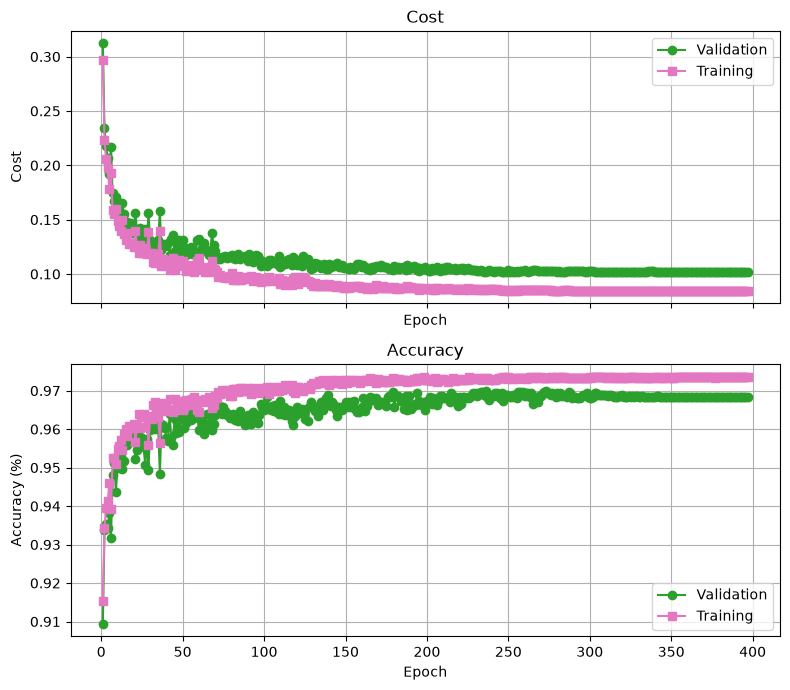

In [6]:
import ssl
import certifi
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from numpy.random import default_rng

#Import the required libraries
# Fix HTTPS certificate verification before importing torchvision
ssl._create_default_https_context = (
    lambda: ssl.create_default_context(cafile=certifi.where())
)

# Download MNIST datasets
train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
)

# Read raw MNIST binary files
def load_dataset(path, is_label=False):
    offset = 8 if is_label else 16

    with open(path, "rb") as file:
        data = np.frombuffer(
            file.read(),
            dtype=np.uint8,
            offset=offset,
        )

    return data


# File paths
data_dir = "./data/MNIST/raw"

X_train = load_dataset(
    f"{data_dir}/train-images-idx3-ubyte"
)

y_train = load_dataset(
    f"{data_dir}/train-labels-idx1-ubyte",
    is_label=True,
)

X_test = load_dataset(
    f"{data_dir}/t10k-images-idx3-ubyte"
)

y_test = load_dataset(
    f"{data_dir}/t10k-labels-idx1-ubyte",
    is_label=True,
)

# Reshape images: 28 x 28 = 784 pixels
X_train = X_train.reshape(60000, 784)
X_test = X_test.reshape(10000, 784)


'''# Check the results
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Visualize some samples from the training dataset
fig, axes = plt.subplots(4, 10, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image, cmap="gray")
    ax.set_title(f"label = {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()'''


# Convert pixels from 0-255 to 0.0-1.0, avoiding overflow when multiplying by weights
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# One-hot encode labels
identity_matrix = np.eye(10)

y_train = identity_matrix[y_train]
y_test = identity_matrix[y_test]


#Some useful functions for the neural network
def relu(x):
    return np.maximum(0, x)

def batch_softmax(x):
    row_max = np.max(x, axis = 1, keepdims = True)
    exp_x = np.exp(x - row_max)
    return exp_x / np.sum(exp_x, axis = 1, keepdims = True)

def batch_cross_entropy(y, y_hat): 
    total_loss = -np.sum(y * np.log(y_hat + 1e-15), axis=1, keepdims=True) #prevent log 0
    return np.mean(total_loss)

def diff_relu(x):
    return (x > 0).astype(float)


def augment_batch(X_batch, augmentation_rng, max_shift=2):
    """Shift each 28x28 image independently; fill uncovered pixels with zero."""
    images = X_batch.reshape(-1, 28, 28)
    shifted = np.zeros_like(images)
    offsets = augmentation_rng.integers(-max_shift, max_shift + 1,
                                        size=(len(images), 2))
    for image_index, (dy, dx) in enumerate(offsets):
        # Copy overlapping pixels; do not wrap edge pixels to the opposite side.
        src_y = slice(max(0, -dy), min(28, 28 - dy))
        src_x = slice(max(0, -dx), min(28, 28 - dx))
        dst_y = slice(max(0, dy), min(28, 28 + dy))
        dst_x = slice(max(0, dx), min(28, 28 + dx))
        shifted[image_index, dst_y, dst_x] = images[image_index, src_y, src_x]
    return shifted.reshape(X_batch.shape)


#Initialize weights and biases
rng = default_rng(seed = 42)
limit = np.sqrt(6 / 784)
w1 = rng.uniform(low = -limit, high = limit, size = (784, 32)) #Mind the defference between the regression and the NN, because Regression only passes one input, while NN passes a batch of inputs, so after one Node, the result is still a matix rather than a value.
limit = np.sqrt(6 / 32)
w2 = rng.uniform(low=-limit, high=limit, size=(32, 32))
w3 = rng.uniform(low=-limit, high=limit, size=(32, 32))
w4 = rng.uniform(low=-limit, high=limit, size=(32, 10))

b1 = np.zeros((1, 32))
b2 = np.zeros((1, 32))
b3 = np.zeros((1, 32))
b4 = np.zeros((1, 10))


#Train-validation split
split = int(0.95 * len(X_train))
shuffle = rng.permutation(len(X_train))
X_train, y_train = X_train[shuffle], y_train[shuffle]
X_train_split = X_train[:split]
y_train_split = y_train[:split]
X_val_split = X_train[split:]
y_val_split = y_train[split:]

#Iteration parameters
epochs = 1000
batch_size = 32
max_shift = 2  # Random translation by up to 2 pixels; set to 0 to disable.
augmentation_rng = default_rng(seed=42)  # Separate from weights/shuffling/dropout.

# Early stopping parameters
patience  = 18
minidelta = 0.0001
patience_counter = 0

#checkpoint parameters
best_val_cost = np.inf
best_w1, best_w2, best_w3, best_w4 = None, None, None, None
best_b1, best_b2, best_b3, best_b4 = None, None, None, None

#lr reduction parameters
lr = 0.05 
min_lr = 1e-6
lr_reduction_factor = 0.5
lr_maxcon_reductions = 8 
lr_reduction_counter = 0

#L2 regularization parameters
lambda_ = 0.15

#Dropout parameters
pkeep = 0.9

#Tracking validation and training cost and accuracy
batches = (len(X_train_split) + batch_size - 1) // batch_size
val_cost_list = []
val_accuracy = []
train_cost_list = []
train_accuracy = []


for i in range(epochs):
    shuffle = rng.permutation(len(X_train_split))
    X_train_split, y_train_split = X_train_split[shuffle], y_train_split[shuffle]
    batch_count = 0
    for j in range(0, len(X_train_split), batch_size):
        batch_count += 1
        end = j + batch_size
        X_train_batch = X_train_split[j:end]
        y_train_batch = y_train_split[j:end]
        X_train_batch = augment_batch(X_train_batch, augmentation_rng, max_shift)

        #Forward Pass
        z1 = np.dot(X_train_batch, w1) + b1
        a1 = relu(z1)

        a1_mask = rng.binomial(1, pkeep, size = a1.shape)
        a1_mask = a1_mask.astype(float)
        a1 *= a1_mask / pkeep

        z2 = np.dot(a1, w2) + b2
        a2 = relu(z2)

        a2_mask = rng.binomial(1, pkeep, size = a2.shape)
        a2_mask = a2_mask.astype(float)
        a2 *= a2_mask / pkeep

        z3 = np.dot(a2, w3) + b3
        a3 = relu(z3)

        a3_mask = rng.binomial(1, pkeep, size = a3.shape)
        a3_mask = a3_mask.astype(float)
        a3 *= a3_mask / pkeep

        z4 = np.dot(a3, w4) + b4
        a4 = batch_softmax(z4)

        cost = batch_cross_entropy(y_train_batch, a4)

        #Backward Pass
        delta4 = a4 - y_train_batch
        delta3 = np.dot(delta4, w4.T) * diff_relu(z3) * (a3_mask / pkeep)
        delta2 = np.dot(delta3, w3.T) * diff_relu(z2) * (a2_mask / pkeep)
        delta1 = np.dot(delta2, w2.T) * diff_relu(z1) * (a1_mask / pkeep)

        dw4 = np.dot(a3.T, delta4) / X_train_batch.shape[0]
        dw3 = np.dot(a2.T, delta3) / X_train_batch.shape[0]
        dw2 = np.dot(a1.T, delta2) / X_train_batch.shape[0]
        dw1 = np.dot(X_train_batch.T, delta1) / X_train_batch.shape[0]
        

        db4 = np.sum(delta4, axis=0, keepdims=True) / X_train_batch.shape[0]
        db3 = np.sum(delta3, axis=0, keepdims=True) / X_train_batch.shape[0]
        db2 = np.sum(delta2, axis=0, keepdims=True) / X_train_batch.shape[0]
        db1 = np.sum(delta1, axis=0, keepdims=True) / X_train_batch.shape[0]    

        w1 -= (lr * (dw1 + (lambda_ * w1) / X_train_split.shape[0]))
        w2 -= (lr * (dw2 + (lambda_ * w2) / X_train_split.shape[0]))
        w3 -= (lr * (dw3 + (lambda_ * w3) / X_train_split.shape[0]))
        w4 -= (lr * (dw4 + (lambda_ * w4) / X_train_split.shape[0]))

        b1 -= lr * db1
        b2 -= lr * db2
        b3 -= lr * db3
        b4 -= lr * db4
    
    

    #Validation
    z1_val = np.dot(X_val_split, w1) + b1
    a1_val = relu(z1_val)
    z2_val = np.dot(a1_val, w2) + b2
    a2_val = relu(z2_val)
    z3_val = np.dot(a2_val, w3) + b3
    a3_val = relu(z3_val)
    z4_val = np.dot(a3_val, w4) + b4
    a4_val = batch_softmax(z4_val)

    val_cost = batch_cross_entropy(y_val_split, a4_val)
    val_cost_list.append(val_cost)
    
    predictions = np.argmax(a4_val, axis=1)
    labels = np.argmax(y_val_split, axis=1)
    accuracy = np.mean(predictions == labels)
    val_accuracy.append(accuracy)

    #Training
    z1_train = np.dot(X_train_split, w1) + b1
    a1_train = relu(z1_train)   
    z2_train = np.dot(a1_train, w2) + b2
    a2_train = relu(z2_train)
    z3_train = np.dot(a2_train, w3) + b3
    a3_train = relu(z3_train)
    z4_train = np.dot(a3_train, w4) + b4
    a4_train = batch_softmax(z4_train)

    train_cost = batch_cross_entropy(y_train_split, a4_train)
    train_cost_list.append(train_cost)
    train_predictions = np.argmax(a4_train, axis=1)
    train_labels = np.argmax(y_train_split, axis=1)
    train_acc = np.mean(train_predictions == train_labels)
    train_accuracy.append(train_acc)
    
    #Print progress every 100 epochs
    if (i + 1) % 100 == 0:
        print(f"Epoch {i + 1}/{epochs}, Validation Cost: {val_cost:.4f}, Training Cost: {train_cost:.4f}")

    # Early Stopping & lr reduction
    if val_cost < best_val_cost:
        best_w1, best_w2, best_w3, best_w4 = np.copy(w1), np.copy(w2), np.copy(w3), np.copy(w4)
        best_b1, best_b2, best_b3, best_b4 = np.copy(b1), np.copy(b2), np.copy(b3), np.copy(b4)

    if best_val_cost - val_cost > minidelta:
        best_val_cost = val_cost
        patience_counter = 0
        lr_reduction_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            if lr * lr_reduction_factor >= min_lr and lr_reduction_counter < lr_maxcon_reductions:
                lr *= lr_reduction_factor
                print(f"Epoch {i + 1}: Reducing learning rate to {lr:.6f}")
                patience_counter = 0
                lr_reduction_counter += 1
            else:
                print(f"Epoch {i + 1}: Early stopping triggered.")
                break



test_z1 = np.dot(X_test, best_w1) + best_b1
test_a1 = relu(test_z1)
test_z2 = np.dot(test_a1, best_w2) + best_b2
test_a2 = relu(test_z2)
test_z3 = np.dot(test_a2, best_w3) + best_b3
test_a3 = relu(test_z3)
test_z4 = np.dot(test_a3, best_w4) + best_b4
test_a4 = batch_softmax(test_z4)

test_predictions = np.argmax(test_a4, axis=1)
test_labels = np.argmax(y_test, axis=1)
test_accuracy = np.mean(np.equal(test_predictions, test_labels))
print(f"Test Accuracy: {test_accuracy:.4f}")



fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# Cost graph
epoch_numbers = range(1, len(val_cost_list) + 1)
ax1.plot(epoch_numbers, val_cost_list, marker="o", color="tab:green", label="Validation")
ax1.plot(epoch_numbers, train_cost_list, marker="s", color="tab:pink", label="Training")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cost")
ax1.set_title("Cost")
ax1.grid(True)
ax1.legend()

# Accuracy graph
ax2.plot(epoch_numbers, val_accuracy, marker="o", color="tab:green", label="Validation")
ax2.plot(epoch_numbers, train_accuracy, marker="s", color="tab:pink", label="Training")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Accuracy")
ax2.grid(True)
ax2.legend()


plt.tight_layout()
plt.show()


##### 4.2.3.2 Results and Conclusion

The **784 → 32 → 32 → 32 → 10** model achieved **97.27% test accuracy**, improving on the augmented baseline's **94.54%** by **2.73 percentage points**. At epoch 300, training and validation losses were **0.0847 and 0.1026**. Both curves settled with a small fitting gap and no sustained late validation-loss increase. Early stopping occurred at epoch **397**.

However, the result was **0.26 percentage points below the wider-only model's 97.53%**, and validation loss was similar. The extra layer therefore provided no observed additional benefit in this run. Two 32-neuron hidden layers may already supply useful representations; added depth also introduces another ReLU/dropout stage and more optimization demands.

**My conclusion:** increasing width was the more useful change in these experiments. Combining width and depth substantially improved the baseline but did not outperform widening alone. This remains a single-run observation; a fixed split and multiple paired seeds are needed for a stronger comparison. (I leave that additional experiment for future work, as this notebook is already quite long!)


#### 4.2.4 Is Bigger Always Better? Potential Training Problems

A larger network offers more capacity, but does not guarantee better learning or generalization. In these runs, adding depth to the wider network did not improve test accuracy. I therefore checked two potential obstacles in the **784 → 32 → 32 → 32 → 10** model. The results below cover the supplied diagnostic records from **epochs 320–397**.

##### 4.2.4.1 Vanishing or Exploding Gradients

**Why consider this?** Backpropagation repeatedly multiplies by weight matrices and activation derivatives. Greater depth introduces more such operations: an imbalance can shrink gradients until early layers barely learn, or amplify them until updates become unstable. This is a risk to monitor, not an inevitable consequence of increasing depth.

The diagnostics recorded each batch's gradients and deltas, then summarized their RMS magnitudes per epoch. RMS means $\sqrt{\operatorname{mean}(x^2)}$, allowing comparison of typical entry magnitudes across differently sized matrices.

| Layer | Epoch-mean weight-gradient RMS range | Epoch-mean delta RMS range |
| :--- | :--- | :--- |
| 1 | 0.00683–0.00709 | 0.123–0.128 |
| 2 | 0.01784–0.01863 | 0.0912–0.0946 |
| 3 | 0.01253–0.01301 | 0.0717–0.0742 |
| 4 | 0.01841–0.01920 | 0.0924–0.0951 |

**Result:** the magnitudes remained stable, and delta did not collapse toward the first layer. No nonfinite-value failure occurred, while training and validation loss remained near 0.0845 and 0.1020. The smaller first-layer weight gradient alone is not evidence of vanishing, because layer inputs and parameter scales differ. Likewise, an occasional maximum gradient of 2.017 is not evidence of explosion without sustained growth or instability.

**Finding:** no clear evidence of severe gradient vanishing or explosion in the monitored late-training interval.

##### 4.2.4.2 ReLU Neurons Remaining Inactive

**Why consider this?** ReLU outputs zero for nonpositive pre-activations, and the implementation passes no gradient there. If a neuron remains nonpositive for nearly all relevant inputs, its incoming weights receive little learning signal, reducing the network's useful capacity. 

Each epoch, the diagnostics evaluated the **same 1,024 unaugmented training images with dropout disabled** and measured the fraction of images producing a positive pre-activation for each neuron.

| Hidden layer | Lowest neuron activation rate during the interval | Neurons with activation rate ≤1% | Neurons inactive for ≥10 consecutive epochs |
| :--- | :--- | :--- | :--- |
| ReLU 1 | About 5.0% | None | None |
| ReLU 2 | About 12.7%–12.9% | None | None |
| ReLU 3 | About 18.1%–18.2% | None | None |

**Result:** every hidden neuron activated on some probe images, and neither inactivity flag was triggered. A neuron active on only 5% of these images may be selective for particular features; that alone does not make it a dead neuron. Dropout cannot explain these activity statistics because it was disabled during the check.

**Finding:** no evidence of persistently inactive ReLU neurons on this fixed probe during epochs 320–397. This is a sample-based observation, so the conclusion should be limited to the monitored images and epochs.

**Conclusion:** neither diagnostic supports these two problems as the explanation for the lack of benefit from extra depth in this run. However, these problems remain worth checking when a larger neural network gives disappointing results.


## 5. Conclusion (Finally!)

### 5.1 Recap — Why and What Did I Write?

First, I would like to thank Maitreya-Bhatkhande for the original code on GitHub and acknowledge the MNIST dataset, which is derived from NIST data. I would also like to thank OpenAI’s Codex for answering my questions and helping me organize my writing and formatting.

As a high school student and a beginner in this field, I encountered many questions and difficulties while learning these concepts. That is why I wrote this notebook: to record what I came to understand and what I could improve, in the hope that these notes might also help others.

Why implement a neural network from scratch instead of using PyTorch or TensorFlow? I plan to discuss those frameworks in other files, though not in detail here. When I first learned TensorFlow, I was filled with curiosity and wanted to understand what was happening beneath the framework. I also wanted to develop the ability to inspect and modify a model when problems arose. That curiosity kept me working through this challenging material for a long time.

In the first part, I included detailed mathematical derivations because I believe mathematics is fundamental to AI. Matrix operations were especially difficult for me, so I worked through the matrices explicitly and explained the meaning of each row, column, and multiplication. Once the calculations finally made sense, I was fascinated by how beautifully these pieces fit together. I hope these explanations help others climb past the same difficulty and enjoy the view from the top.

In the second part, I explored the learning rate. Before learning about learning-rate reduction, I had only used a fixed learning rate. I began by trying several fixed values—a simple but useful approach—and then improved the comparison by controlling the experimental conditions. I also discussed learning-rate reduction and when it might be appropriate for this task.

In the third part, I examined weight initialization. This may seem like a less obvious topic to focus on, but I enjoy mathematics. When I saw the initialization formula in the original GitHub code, I wanted to know why it had that form and whether another choice might be better. Studying it also revealed an interesting connection between neural networks and probability.

The fourth part addressed training problems and possible improvements. Overfitting was the clearest problem I encountered, so I discussed it first. L2 regularization and dropout are common approaches, but I also wondered whether slightly changing the training images could help. I later learned that this idea is called data augmentation. I then tried something I had wanted to do for a long time: build wider and deeper neural networks. At first, I imagined that bigger would always mean stronger and better. The experiments showed that this is not necessarily true; architecture and training conditions matter, and a relatively simple network can also perform well.

Working through these questions has felt like climbing a mountain. Reaching the summit makes the effort worthwhile—and reveals more peaks to explore.

### 5.2 Remaining Questions

I used the idea of controlled experiments, familiar from chemistry and biology, but not every comparison held all conditions strictly constant. Some findings also need more repeated experiments before stronger conclusions can be drawn, as noted throughout the notebook.

Some explanations or pieces of code may still need refinement, and this notebook does not cover every possible improvement or solution. I would appreciate suggestions and feedback from anyone who reads it.

## THANK YOU FOR YOUR READING!!!
